In [1]:
import sys
import radiomics

print("Python:", sys.version)
print("PyRadiomics:", radiomics.__version__)

Python: 3.11.18 (main, Oct 26 2026, 13:58:42) [Clang 23.1.3 ]
PyRadiomics: 3.1.1.dev111+g8ed579383


In [2]:
from pathlib import Path
import SimpleITK as sitk

# Define dataset location
project_directory = Path.cwd().parent
dataset_directory = project_directory / "Description and Sample of the DataSet-20261006"

# Select the first nodule
nodule_filename = "LIDC-IDRI-0001_R_1.nii.gz"

# Define image and mask paths
image_path = dataset_directory / "VOIs" / "image" / nodule_filename
mask_path = dataset_directory / "VOIs" / "nodule_mask" / nodule_filename

# Load image and mask
nodule_image = sitk.ReadImage(str(image_path))
nodule_mask = sitk.ReadImage(str(mask_path))

# Inspect image properties
print("Image size:", nodule_image.GetSize())
print("Mask size:", nodule_mask.GetSize())

print("Image spacing:", nodule_image.GetSpacing())
print("Mask spacing:", nodule_mask.GetSpacing())

Image size: (53, 64, 11)
Mask size: (53, 64, 11)
Image spacing: (0.703125, 0.703125, 2.5)
Mask spacing: (0.703125, 0.703125, 2.5)


In [3]:
from radiomics import featureextractor

# Initialize PyRadiomics feature extractor
extractor = featureextractor.RadiomicsFeatureExtractor()

# Extract features from the nodule image and mask
extracted_features = extractor.execute(
    str(image_path),
    str(mask_path)
)

# Display selected radiomic features
features_to_display = [
    "original_shape_VoxelVolume",
    "original_shape_SurfaceArea",
    "original_shape_Sphericity",
    "original_firstorder_Mean",
    "original_glcm_Contrast"
]

for feature_name in features_to_display:
    feature_value = extracted_features.get(feature_name)
    print(feature_name, ":", feature_value)

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


original_shape_VoxelVolume : 8091.8426513671875
original_shape_SurfaceArea : 2956.0448042649614
original_shape_Sphericity : 0.6552448557268963
original_firstorder_Mean : -161.66228807087217
original_glcm_Contrast : 80.44228438638376


In [4]:
# Identify the extracted radiomic features
radiomic_feature_names = []

for feature_name in extracted_features:

    if feature_name.startswith("original_"):
        radiomic_feature_names.append(feature_name)


# Display the number of extracted features
print("Total radiomic features:", len(radiomic_feature_names))

# Display the first 15 feature names
print("\nFirst 15 features:")

for feature_name in radiomic_feature_names[:15]:
    print(feature_name)

Total radiomic features: 107

First 15 features:
original_shape_Elongation
original_shape_Flatness
original_shape_LeastAxisLength
original_shape_MajorAxisLength
original_shape_Maximum2DDiameterColumn
original_shape_Maximum2DDiameterRow
original_shape_Maximum2DDiameterSlice
original_shape_Maximum3DDiameter
original_shape_MeshVolume
original_shape_MinorAxisLength
original_shape_Sphericity
original_shape_SurfaceArea
original_shape_SurfaceVolumeRatio
original_shape_VoxelVolume
original_firstorder_10Percentile


In [5]:
# Count features by category
feature_counts = {}

for feature_name in radiomic_feature_names:

    # Extract the feature category from its name
    feature_category = feature_name.split("_")[1]

    if feature_category not in feature_counts:
        feature_counts[feature_category] = 0

    feature_counts[feature_category] += 1


# Display results
for category, count in feature_counts.items():
    print(f"{category}: {count} features")

shape: 14 features
firstorder: 18 features
glcm: 24 features
gldm: 14 features
glrlm: 16 features
glszm: 16 features
ngtdm: 5 features


In [6]:
# Define image and mask directories
image_directory = dataset_directory / "VOIs" / "image"
mask_directory = dataset_directory / "VOIs" / "nodule_mask"

# Select the first 5 nodule images
image_files = sorted(image_directory.glob("*.nii.gz"))[:5]

# Test feature extraction
for image_file in image_files:

    mask_file = mask_directory / image_file.name

    try:
        features = extractor.execute(
            str(image_file),
            str(mask_file)
        )

        print(f"{image_file.name}: Extraction successful")

    except Exception as error:
        print(f"{image_file.name}: Extraction failed")
        print(error)

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


LIDC-IDRI-0001_R_1.nii.gz: Extraction successful
LIDC-IDRI-0003_R_2.nii.gz: Extraction successful
LIDC-IDRI-0003_R_3.nii.gz: Extraction successful


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


LIDC-IDRI-0003_R_4.nii.gz: Extraction successful


GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


LIDC-IDRI-0004_R_1.nii.gz: Extraction successful


In [7]:
import pandas as pd

# Store the extracted features of each nodule
nodule_records = []

for image_file in image_files:

    mask_file = mask_directory / image_file.name

    # Extract radiomic features
    features = extractor.execute(
        str(image_file),
        str(mask_file)
    )

    # Extract patient and nodule identifiers
    filename = image_file.name.removesuffix(".nii.gz")
    patient_id, nodule_id = filename.split("_R_")

    # Create a record for this nodule
    nodule_record = {
        "patient_id": patient_id,
        "nodule_id": int(nodule_id)
    }

    # Add the radiomic features to the record
    for feature_name in radiomic_feature_names:
        nodule_record[feature_name] = float(features[feature_name])

    nodule_records.append(nodule_record)


# Convert the records into a DataFrame
radiomics_dataset = pd.DataFrame(nodule_records)

print("Dataset dimensions:", radiomics_dataset.shape)

display(radiomics_dataset.iloc[:, :7])

GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


Dataset dimensions: (5, 109)


,patient_id,nodule_id,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn
0,LIDC-IDRI-0001,1,0.969487,0.860174,21.003480,24.417710,30.103986
1,LIDC-IDRI-0003,2,0.888136,0.581619,18.039371,31.015808,35.666423
2,LIDC-IDRI-0003,3,0.673941,0.649285,7.949830,12.243980,13.469311
3,LIDC-IDRI-0003,4,0.835362,0.804038,11.747163,14.610216,20.267377
4,LIDC-IDRI-0004,1,0.851577,0.779727,5.314192,6.815455,7.811263


In [8]:
import logging

# Hide repetitive GLCM warnings
logging.getLogger("radiomics.glcm").setLevel(logging.ERROR)

# Find all available nodule images
all_image_files = sorted(image_directory.glob("*.nii.gz"))

# Prepare lists for results and errors
nodule_records = []
failed_extractions = []

print("Images to process:", len(all_image_files))

# Extract features from each nodule
for image_number, image_file in enumerate(all_image_files, start=1):

    mask_file = mask_directory / image_file.name

    if not mask_file.exists():
        failed_extractions.append((image_file.name, "Missing mask"))
        continue

    try:
        # Extract radiomic features
        extracted_features = extractor.execute(
            str(image_file),
            str(mask_file)
        )

        # Identify the patient and nodule
        filename = image_file.name.removesuffix(".nii.gz")
        patient_id, nodule_id = filename.split("_R_")

        nodule_record = {
            "patient_id": patient_id,
            "nodule_id": int(nodule_id)
        }

        # Add the extracted features
        for feature_name in radiomic_feature_names:
            feature_value = extracted_features[feature_name]
            nodule_record[feature_name] = float(feature_value)

        nodule_records.append(nodule_record)

    except Exception as error:
        failed_extractions.append((image_file.name, str(error)))

    # Display progress every 25 images
    if image_number % 25 == 0:
        print(f"Processed {image_number} of {len(all_image_files)} images")


# Create the complete dataset
radiomics_dataset = pd.DataFrame(nodule_records)

# Save the extracted features
output_path = project_directory / "results" / "radiomics_features.csv"

radiomics_dataset.to_csv(output_path, index=False)

# Display extraction summary
print("\nExtraction completed")
print("Successful extractions:", len(nodule_records))
print("Failed extractions:", len(failed_extractions))
print("Dataset dimensions:", radiomics_dataset.shape)
print("Saved to:", output_path)

display(radiomics_dataset.head())

Images to process: 994
Processed 25 of 994 images
Processed 50 of 994 images
Processed 75 of 994 images
Processed 100 of 994 images
Processed 125 of 994 images
Processed 150 of 994 images
Processed 175 of 994 images
Processed 200 of 994 images
Processed 225 of 994 images
Processed 250 of 994 images
Processed 275 of 994 images
Processed 300 of 994 images
Processed 325 of 994 images
Processed 350 of 994 images
Processed 375 of 994 images
Processed 400 of 994 images
Processed 425 of 994 images
Processed 450 of 994 images
Processed 475 of 994 images
Processed 500 of 994 images
Processed 525 of 994 images
Processed 550 of 994 images
Processed 575 of 994 images
Processed 600 of 994 images
Processed 625 of 994 images
Processed 650 of 994 images
Processed 675 of 994 images
Processed 700 of 994 images
Processed 725 of 994 images
Processed 750 of 994 images
Processed 775 of 994 images
Processed 800 of 994 images
Processed 825 of 994 images
Processed 850 of 994 images
Processed 875 of 994 images


,patient_id,nodule_id,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,LIDC-IDRI-0001,1,0.969487,0.860174,21.003480,24.417710,30.103986,33.842466,34.738929,36.390152,...,457.133374,0.004362,6.712857,0.407668,356.247040,0.506478,0.001145,3691.077373,0.494586,1.211626
1,LIDC-IDRI-0003,2,0.888136,0.581619,18.039371,31.015808,35.666423,35.035215,33.991022,39.760410,...,323.295565,0.005548,6.889498,0.370646,140.357697,0.709235,0.001520,3044.802147,0.443948,1.437845
2,LIDC-IDRI-0003,3,0.673941,0.649285,7.949830,12.243980,13.469311,11.145619,13.227134,14.151461,...,228.034156,0.018957,5.873319,0.654545,2.017747,0.208307,0.010943,3930.638483,1.237060,6.090407
3,LIDC-IDRI-0003,4,0.835362,0.804038,11.747163,14.610216,20.267377,20.267377,14.788385,20.333672,...,395.403776,0.009473,6.071002,0.525952,55.417893,0.185347,0.004468,4320.436125,1.157649,4.261567
4,LIDC-IDRI-0004,1,0.851577,0.779727,5.314192,6.815455,7.811263,7.962592,7.800700,8.194283,...,579.565211,0.023466,5.902933,0.706250,1.074791,0.059115,0.025284,9932.526324,1.377353,52.136354


In [9]:
import numpy as np

# Select only the radiomic features
feature_data = radiomics_dataset.drop(
    columns=["patient_id", "nodule_id"]
)

# Check for missing values
missing_values = feature_data.isna().sum().sum()

# Check for infinite values
infinite_values = np.isinf(feature_data.to_numpy()).sum()

# Check for duplicated nodules
duplicated_nodules = radiomics_dataset.duplicated(
    subset=["patient_id", "nodule_id"]
).sum()

print("Missing values:", missing_values)
print("Infinite values:", infinite_values)
print("Duplicated nodules:", duplicated_nodules)

Missing values: 0
Infinite values: 0
Duplicated nodules: 0


In [10]:
# Load the original metadata
metadata_path = dataset_directory / "MetadatabyAnnotation.xlsx"
metadata = pd.read_excel(metadata_path)

# Identify suspicious malignancy assessments
metadata["suspicious_assessment"] = (
    metadata["Malignancy_value"] > 3
)

# Group annotations belonging to the same nodule
nodule_identifiers = ["patient_id", "nodule_id"]

nodule_assessments = metadata.groupby(
    nodule_identifiers,
    as_index=False
).agg(
    suspicious_count=("suspicious_assessment", "sum"),
    annotation_count=("Malignancy_value", "size")
)

# Apply the classification rule defined in LUNA16
nodule_assessments["malignancy_label"] = (
    nodule_assessments["suspicious_count"] >= 2
).astype(int)

# Inspect the results
print("Total classified nodules:", len(nodule_assessments))

print("\nMalignancy distribution:")
print(nodule_assessments["malignancy_label"].value_counts())

print("\nNodules with more than 4 annotation records:")
print((nodule_assessments["annotation_count"] > 4).sum())

display(nodule_assessments.head())

Total classified nodules: 996

Malignancy distribution:
malignancy_label
0    650
1    346
Name: count, dtype: int64

Nodules with more than 4 annotation records:
6


,patient_id,nodule_id,suspicious_count,annotation_count,malignancy_label
0,LIDC-IDRI-0001,1,4,4,1
1,LIDC-IDRI-0003,2,3,4,1
2,LIDC-IDRI-0003,3,2,4,1
3,LIDC-IDRI-0003,4,2,4,1
4,LIDC-IDRI-0004,1,0,4,0


In [11]:
# Select the information needed for classification
malignancy_data = nodule_assessments[
    ["patient_id", "nodule_id", "malignancy_label"]
]

# Combine radiomic features with malignancy labels
classification_dataset = radiomics_dataset.merge(
    malignancy_data,
    on=["patient_id", "nodule_id"],
    how="left",
    validate="one_to_one",
    indicator=True
)

# Check whether all nodules found their metadata
unmatched_nodules = classification_dataset[
    classification_dataset["_merge"] != "both"
]

print("Total nodules:", len(classification_dataset))
print("Nodules without malignancy label:", len(unmatched_nodules))

# Remove the temporary merge indicator
classification_dataset = classification_dataset.drop(
    columns=["_merge"]
)

# Display the class distribution
print("\nMalignancy distribution:")
print(classification_dataset["malignancy_label"].value_counts())

print("\nDataset dimensions:", classification_dataset.shape)

display(classification_dataset.head())

Total nodules: 994
Nodules without malignancy label: 0

Malignancy distribution:
malignancy_label
0    650
1    344
Name: count, dtype: int64

Dataset dimensions: (994, 110)


,patient_id,nodule_id,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,...,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength,malignancy_label
0,LIDC-IDRI-0001,1,0.969487,0.860174,21.003480,24.417710,30.103986,33.842466,34.738929,36.390152,...,0.004362,6.712857,0.407668,356.247040,0.506478,0.001145,3691.077373,0.494586,1.211626,1
1,LIDC-IDRI-0003,2,0.888136,0.581619,18.039371,31.015808,35.666423,35.035215,33.991022,39.760410,...,0.005548,6.889498,0.370646,140.357697,0.709235,0.001520,3044.802147,0.443948,1.437845,1
2,LIDC-IDRI-0003,3,0.673941,0.649285,7.949830,12.243980,13.469311,11.145619,13.227134,14.151461,...,0.018957,5.873319,0.654545,2.017747,0.208307,0.010943,3930.638483,1.237060,6.090407,1
3,LIDC-IDRI-0003,4,0.835362,0.804038,11.747163,14.610216,20.267377,20.267377,14.788385,20.333672,...,0.009473,6.071002,0.525952,55.417893,0.185347,0.004468,4320.436125,1.157649,4.261567,1
4,LIDC-IDRI-0004,1,0.851577,0.779727,5.314192,6.815455,7.811263,7.962592,7.800700,8.194283,...,0.023466,5.902933,0.706250,1.074791,0.059115,0.025284,9932.526324,1.377353,52.136354,0


In [12]:
# Identify nodules with more than four annotation records
unusual_nodules = nodule_assessments[
    nodule_assessments["annotation_count"] > 4
]

# Find their original annotations
unusual_annotations = metadata.merge(
    unusual_nodules[["patient_id", "nodule_id"]],
    on=["patient_id", "nodule_id"],
    how="inner"
)

# Display relevant information
columns_to_display = [
    "patient_id",
    "nodule_id",
    "seriesuid",
    "anotation_id",
    "Malignancy_value",
    "diameter_mm"
]

display(
    unusual_annotations[columns_to_display].sort_values(
        ["patient_id", "nodule_id", "anotation_id"]
    )
)

,patient_id,nodule_id,seriesuid,anotation_id,Malignancy_value,diameter_mm
0,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1717,4,15.992350
1,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1718,3,15.992350
2,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1719,5,15.992350
3,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1720,5,15.992350
4,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1721,4,15.992350
5,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1722,4,15.992350
6,LIDC-IDRI-0252,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.330544495001...,1981,5,16.828939
7,LIDC-IDRI-0252,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.330544495001...,1982,3,16.828939
8,LIDC-IDRI-0252,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.330544495001...,1983,5,16.828939
9,LIDC-IDRI-0252,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.330544495001...,1984,4,16.828939


In [13]:
# Select nodules with more than four annotations
unusual_nodules = nodule_assessments[
    nodule_assessments["annotation_count"] > 4
]

# Retrieve their original metadata records
unusual_annotations = metadata.merge(
    unusual_nodules[["patient_id", "nodule_id"]],
    on=["patient_id", "nodule_id"],
    how="inner"
)

# Select relevant columns for inspection
columns_to_review = [
    "patient_id",
    "nodule_id",
    "seriesuid",
    "anotation_id",
    "Malignancy_value",
    "diameter_mm"
]

# Display the annotations ordered by nodule
display(
    unusual_annotations[columns_to_review].sort_values(
        by=["patient_id", "nodule_id", "anotation_id"]
    )
)

,patient_id,nodule_id,seriesuid,anotation_id,Malignancy_value,diameter_mm
0,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1717,4,15.992350
1,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1718,3,15.992350
2,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1719,5,15.992350
3,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1720,5,15.992350
4,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1721,4,15.992350
5,LIDC-IDRI-0204,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.149041668385...,1722,4,15.992350
6,LIDC-IDRI-0252,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.330544495001...,1981,5,16.828939
7,LIDC-IDRI-0252,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.330544495001...,1982,3,16.828939
8,LIDC-IDRI-0252,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.330544495001...,1983,5,16.828939
9,LIDC-IDRI-0252,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.330544495001...,1984,4,16.828939


In [14]:
# Count different CT series associated with each nodule
series_per_nodule = metadata.groupby(
    ["patient_id", "nodule_id"]
)["seriesuid"].nunique()

# Identify nodules associated with multiple CT series
nodules_with_multiple_series = series_per_nodule[
    series_per_nodule > 1
]

print("Nodules with multiple CT series:")
display(nodules_with_multiple_series)

Nodules with multiple CT series:


patient_id      nodule_id
LIDC-IDRI-0332  1            2
Name: seriesuid, dtype: int64

In [15]:
# Identify the nodule with ambiguous CT series
ambiguous_nodule = (
    (classification_dataset["patient_id"] == "LIDC-IDRI-0332") &
    (classification_dataset["nodule_id"] == 1)
)

# Exclude the ambiguous nodule
clean_classification_dataset = classification_dataset[
    ~ambiguous_nodule
].copy()

# Save the cleaned dataset
output_path = project_directory / "results" / "classification_dataset.csv"

clean_classification_dataset.to_csv(output_path, index=False)

# Display results
print("Original nodules:", len(classification_dataset))
print("Excluded nodules:", ambiguous_nodule.sum())
print("Final nodules:", len(clean_classification_dataset))

print("\nClass distribution:")
print(clean_classification_dataset["malignancy_label"].value_counts())

Original nodules: 994
Excluded nodules: 1
Final nodules: 993

Class distribution:
malignancy_label
0    650
1    343
Name: count, dtype: int64


In [16]:
from sklearn.model_selection import StratifiedGroupKFold

# Separate radiomic features, labels and patient identifiers
feature_columns = [
    column for column in clean_classification_dataset.columns
    if column.startswith("original_")
]

features = clean_classification_dataset[feature_columns]
labels = clean_classification_dataset["malignancy_label"]
patients = clean_classification_dataset["patient_id"]

# Create a patient-based split
data_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Reserve one fold for testing
splits = data_splitter.split(features, labels, groups=patients)

training_indices, testing_indices = next(splits)

# Create training and testing datasets
training_dataset = clean_classification_dataset.iloc[
    training_indices
].copy()

testing_dataset = clean_classification_dataset.iloc[
    testing_indices
].copy()

# Verify the split
training_patients = set(training_dataset["patient_id"])
testing_patients = set(testing_dataset["patient_id"])

shared_patients = training_patients.intersection(testing_patients)

print("Training nodules:", len(training_dataset))
print("Testing nodules:", len(testing_dataset))
print("Shared patients:", len(shared_patients))

print("\nTraining class distribution:")
print(training_dataset["malignancy_label"].value_counts())

print("\nTesting class distribution:")
print(testing_dataset["malignancy_label"].value_counts())

Training nodules: 793
Testing nodules: 200
Shared patients: 0

Training class distribution:
malignancy_label
0    519
1    274
Name: count, dtype: int64

Testing class distribution:
malignancy_label
0    131
1     69
Name: count, dtype: int64


In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

# Prepare training data
training_features = training_dataset[feature_columns]
training_labels = training_dataset["malignancy_label"]
training_patients = training_dataset["patient_id"]

# Create our first Random Forest classifier
random_forest = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Configure patient-based cross-validation
cross_validation = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the classifier
validation_results = cross_validate(
    random_forest,
    training_features,
    training_labels,
    groups=training_patients,
    cv=cross_validation,
    scoring=["accuracy", "balanced_accuracy", "precision", "recall", "f1"]
)

# Display average performance
for metric in ["accuracy", "balanced_accuracy", "precision", "recall", "f1"]:
    scores = validation_results["test_" + metric]

    print(f"{metric}: {scores.mean():.3f} (+/- {scores.std():.3f})")

accuracy: 0.865 (+/- 0.037)
balanced_accuracy: 0.857 (+/- 0.037)
precision: 0.794 (+/- 0.063)
recall: 0.832 (+/- 0.056)
f1: 0.811 (+/- 0.047)


Testing results:

              precision    recall  f1-score   support

      Benign       0.92      0.95      0.93       131
  Suspicious       0.89      0.84      0.87        69

    accuracy                           0.91       200
   macro avg       0.91      0.89      0.90       200
weighted avg       0.91      0.91      0.91       200



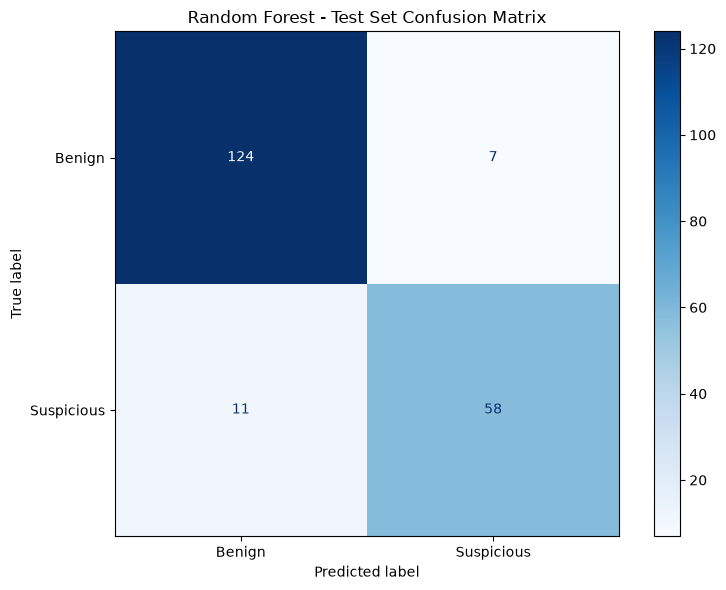

In [18]:
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Train the model using all training nodules
random_forest.fit(training_features, training_labels)

# Prepare the testing dataset
testing_features = testing_dataset[feature_columns]
testing_labels = testing_dataset["malignancy_label"]

# Predict malignancy for the testing nodules
predicted_labels = random_forest.predict(testing_features)

# Display classification performance
print("Testing results:\n")

print(
    classification_report(
        testing_labels,
        predicted_labels,
        target_names=["Benign", "Suspicious"]
    )
)

# Create confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    testing_labels,
    predicted_labels,
    display_labels=["Benign", "Suspicious"],
    cmap="Blues",
    ax=ax
)

ax.set_title("Random Forest - Test Set Confusion Matrix")

plt.tight_layout()

# Save figure before displaying it
fig.savefig(
    project_directory / "results" / "random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Feature,Importance
9,original_shape_MinorAxisLength,0.070991
13,original_shape_VoxelVolume,0.061685
103,original_ngtdm_Coarseness,0.059643
8,original_shape_MeshVolume,0.059144
6,original_shape_Maximum2DDiameterSlice,0.047822
11,original_shape_SurfaceArea,0.046779
2,original_shape_LeastAxisLength,0.035956
12,original_shape_SurfaceVolumeRatio,0.029316
86,original_glszm_GrayLevelNonUniformity,0.027651
70,original_glrlm_GrayLevelNonUniformity,0.026067


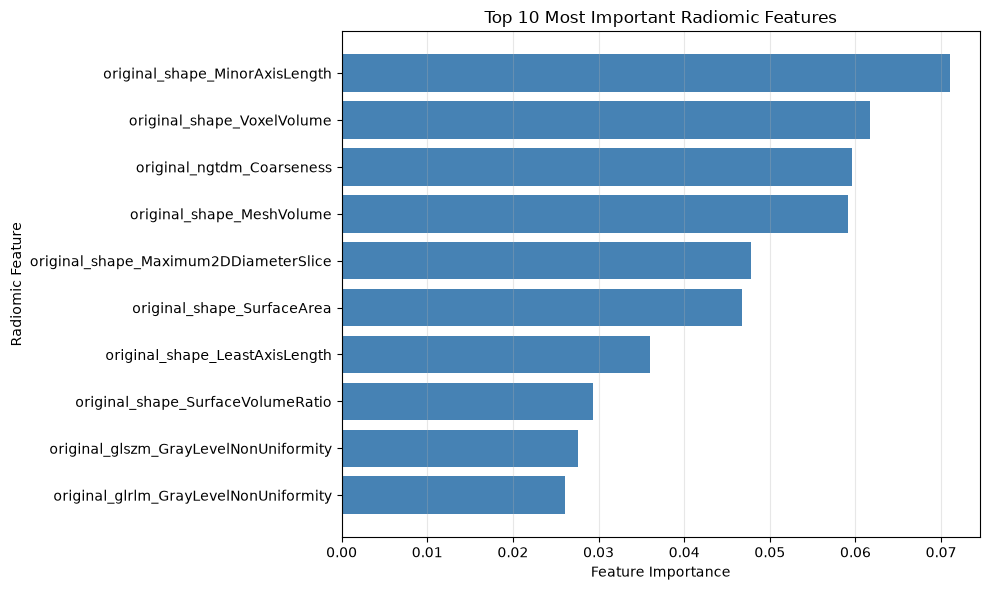

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance values from the trained Random Forest
feature_importance_values = random_forest.feature_importances_

# Create a table with feature names and importance values
feature_importance_table = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": feature_importance_values
})

# Sort features from highest to lowest importance
feature_importance_table = feature_importance_table.sort_values(
    by="Importance",
    ascending=False
)

# Select the 10 most important features
top_10_features = feature_importance_table.head(10)

display(top_10_features)


# Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_10_features["Feature"],
    top_10_features["Importance"],
    color="steelblue"
)

ax.invert_yaxis()

ax.set_title("Top 10 Most Important Radiomic Features")
ax.set_xlabel("Feature Importance")
ax.set_ylabel("Radiomic Feature")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

# Save the figure
fig.savefig(
    project_directory / "results" / "random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
# Select only shape features
shape_feature_columns = []

for feature_name in feature_columns:
    if feature_name.startswith("original_shape_"):
        shape_feature_columns.append(feature_name)

shape_training_features = training_dataset[shape_feature_columns]

# Create a Random Forest using only shape features
shape_random_forest = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Evaluate the reduced model using cross-validation
shape_validation_results = cross_validate(
    shape_random_forest,
    shape_training_features,
    training_labels,
    groups=training_patients,
    cv=cross_validation,
    scoring=["accuracy", "balanced_accuracy", "precision", "recall", "f1"]
)

# Compare both models
print("Original model: 107 features")
print("Reduced model:", len(shape_feature_columns), "features\n")

for metric_name in ["accuracy", "balanced_accuracy", "recall", "f1"]:

    original_scores = validation_results["test_" + metric_name]
    reduced_scores = shape_validation_results["test_" + metric_name]

    print(metric_name)
    print("  Original:", round(original_scores.mean(), 3))
    print("  Reduced: ", round(reduced_scores.mean(), 3))

Original model: 107 features
Reduced model: 14 features

accuracy
  Original: 0.865
  Reduced:  0.856
balanced_accuracy
  Original: 0.857
  Reduced:  0.849
recall
  Original: 0.832
  Reduced:  0.828
f1
  Original: 0.811
  Reduced:  0.799


In [21]:
# Select intensity and texture features
texture_intensity_columns = []

for feature_name in feature_columns:

    if not feature_name.startswith("original_shape_"):
        texture_intensity_columns.append(feature_name)


# Prepare training data
texture_intensity_training = training_dataset[
    texture_intensity_columns
]


# Create a Random Forest without shape features
texture_intensity_forest = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)


# Evaluate using the same patient-based cross-validation
texture_intensity_results = cross_validate(
    texture_intensity_forest,
    texture_intensity_training,
    training_labels,
    groups=training_patients,
    cv=cross_validation,
    scoring=["accuracy", "balanced_accuracy", "precision", "recall", "f1"]
)


# Compare the three models
models = {
    "All features (107)": validation_results,
    "Shape only (14)": shape_validation_results,
    "Intensity + Texture (93)": texture_intensity_results
}

comparison_results = []

for model_name, model_results in models.items():

    model_statistics = {"Model": model_name}

    for metric_name in ["accuracy", "balanced_accuracy", "recall", "f1"]:

        scores = model_results["test_" + metric_name]
        model_statistics[metric_name] = scores.mean()

    comparison_results.append(model_statistics)


comparison_table = pd.DataFrame(comparison_results)

display(comparison_table.round(3))

,Model,accuracy,balanced_accuracy,recall,f1
0,All features (107),0.865,0.857,0.832,0.811
1,Shape only (14),0.856,0.849,0.828,0.799
2,Intensity + Texture (93),0.866,0.857,0.829,0.811


In [22]:
# Separate intensity and texture features
intensity_columns = []
texture_columns = []

for feature_name in feature_columns:

    if feature_name.startswith("original_firstorder_"):
        intensity_columns.append(feature_name)

    elif not feature_name.startswith("original_shape_"):
        texture_columns.append(feature_name)


print("Intensity features:", len(intensity_columns))
print("Texture features:", len(texture_columns))


# Evaluate the model using only intensity features
intensity_results = cross_validate(
    random_forest,
    training_dataset[intensity_columns],
    training_labels,
    groups=training_patients,
    cv=cross_validation,
    scoring=["accuracy", "balanced_accuracy", "recall", "f1"]
)


# Evaluate the model using only texture features
texture_results = cross_validate(
    random_forest,
    training_dataset[texture_columns],
    training_labels,
    groups=training_patients,
    cv=cross_validation,
    scoring=["accuracy", "balanced_accuracy", "recall", "f1"]
)


# Compare all five feature groups
models = {
    "All features (107)": validation_results,
    "Shape only (14)": shape_validation_results,
    "Intensity + Texture (93)": texture_intensity_results,
    "Intensity only (18)": intensity_results,
    "Texture only (75)": texture_results
}

comparison_results = []

for model_name, model_results in models.items():

    model_statistics = {"Model": model_name}

    for metric_name in ["accuracy", "balanced_accuracy", "recall", "f1"]:

        scores = model_results["test_" + metric_name]
        model_statistics[metric_name] = scores.mean()

    comparison_results.append(model_statistics)


comparison_table = pd.DataFrame(comparison_results)

display(comparison_table.round(3))

Intensity features: 18
Texture features: 75


,Model,accuracy,balanced_accuracy,recall,f1
0,All features (107),0.865,0.857,0.832,0.811
1,Shape only (14),0.856,0.849,0.828,0.799
2,Intensity + Texture (93),0.866,0.857,0.829,0.811
3,Intensity only (18),0.855,0.847,0.821,0.796
4,Texture only (75),0.859,0.852,0.829,0.802


In [23]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

# Create the SVM classifier
svm_classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced"
    ))
])

# Evaluate using the same patient-based cross-validation
svm_validation_results = cross_validate(
    svm_classifier,
    training_features,
    training_labels,
    groups=training_patients,
    cv=cross_validation,
    scoring=["accuracy", "balanced_accuracy", "precision", "recall", "f1"]
)

# Compare Random Forest and SVM
models_to_compare = {
    "Random Forest": validation_results,
    "SVM": svm_validation_results
}

comparison_results = []

for model_name, model_results in models_to_compare.items():

    model_statistics = {"Model": model_name}

    for metric_name in ["accuracy", "balanced_accuracy", "precision", "recall", "f1"]:

        metric_scores = model_results["test_" + metric_name]

        model_statistics[metric_name] = metric_scores.mean()

    comparison_results.append(model_statistics)

# Display comparison
svm_comparison_table = pd.DataFrame(comparison_results)

display(svm_comparison_table.round(3))

,Model,accuracy,balanced_accuracy,precision,recall,f1
0,Random Forest,0.865,0.857,0.794,0.832,0.811
1,SVM,0.861,0.865,0.765,0.876,0.814


SVM Testing Results:

              precision    recall  f1-score   support

      Benign       0.91      0.92      0.91       131
  Suspicious       0.84      0.83      0.83        69

    accuracy                           0.89       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.88      0.89      0.88       200



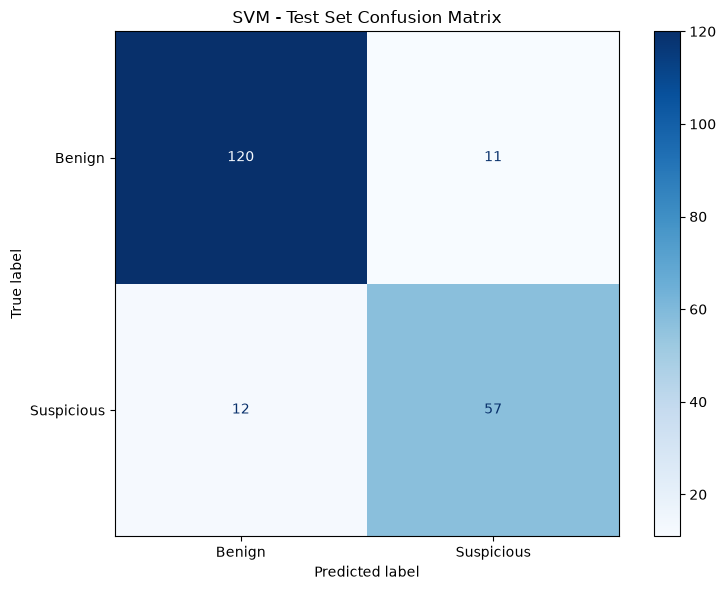

In [24]:
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Train SVM using the complete training set
svm_classifier.fit(training_features, training_labels)

# Prepare the testing data
svm_testing_features = testing_dataset[feature_columns]
svm_testing_labels = testing_dataset["malignancy_label"]

# Predict malignancy using SVM
svm_predictions = svm_classifier.predict(svm_testing_features)

# Display classification metrics
print("SVM Testing Results:\n")

print(
    classification_report(
        svm_testing_labels,
        svm_predictions,
        target_names=["Benign", "Suspicious"]
    )
)

# Create confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    svm_testing_labels,
    svm_predictions,
    display_labels=["Benign", "Suspicious"],
    cmap="Blues",
    ax=ax
)

ax.set_title("SVM - Test Set Confusion Matrix")

plt.tight_layout()

# Save figure in results before displaying
fig.savefig(
    project_directory / "results" / "svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameters to evaluate
svm_parameters = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.001, 0.01, 0.1]
}

# Configure the hyperparameter search
svm_grid_search = GridSearchCV(
    estimator=svm_classifier,
    param_grid=svm_parameters,
    scoring="f1",
    cv=cross_validation,
    n_jobs=-1,
    refit=True
)

# Find the best parameters using only training data
svm_grid_search.fit(
    training_features,
    training_labels,
    groups=training_patients
)

# Display the best configuration
print("Best SVM parameters:")
print(svm_grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(svm_grid_search.best_score_, 3))

Best SVM parameters:
{'svm__C': 100, 'svm__gamma': 0.001}

Best cross-validation F1-score:
0.821


In [26]:
# Store the results of all parameter combinations
svm_tuning_results = pd.DataFrame(
    svm_grid_search.cv_results_
)

# Select the relevant columns
svm_tuning_summary = svm_tuning_results[
    [
        "param_svm__C",
        "param_svm__gamma",
        "mean_test_score",
        "std_test_score"
    ]
].copy()

# Sort configurations by F1-score
svm_tuning_summary = svm_tuning_summary.sort_values(
    by="mean_test_score",
    ascending=False
)

# Display the results
display(svm_tuning_summary.round(3))

# Save results for the report
svm_tuning_summary.to_csv(
    project_directory / "results" / "svm_hyperparameter_tuning.csv",
    index=False
)

,param_svm__C,param_svm__gamma,mean_test_score,std_test_score
13,100.0,0.001,0.821,0.038
5,1.0,0.001,0.819,0.045
9,10.0,0.001,0.819,0.032
0,0.1,scale,0.814,0.036
4,1.0,scale,0.814,0.035
6,1.0,0.01,0.814,0.035
2,0.1,0.01,0.810,0.032
10,10.0,0.01,0.784,0.047
8,10.0,scale,0.784,0.041
1,0.1,0.001,0.777,0.037


In [27]:
from sklearn.base import clone
from sklearn.metrics import f1_score, recall_score, balanced_accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

# Configure the inner cross-validation
inner_cross_validation = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

# Store the evaluation results
nested_validation_results = []

# Evaluate the optimized SVM using outer cross-validation
for fold_number, (train_indices, validation_indices) in enumerate(
    cross_validation.split(
        training_features,
        training_labels,
        groups=training_patients
    ),
    start=1
):

    # Separate training and validation data for this fold
    fold_training_features = training_features.iloc[train_indices]
    fold_training_labels = training_labels.iloc[train_indices]
    fold_training_patients = training_patients.iloc[train_indices]

    fold_validation_features = training_features.iloc[validation_indices]
    fold_validation_labels = training_labels.iloc[validation_indices]

    # Search for the best SVM parameters
    parameter_search = GridSearchCV(
        estimator=clone(svm_classifier),
        param_grid=svm_parameters,
        scoring="f1",
        cv=inner_cross_validation,
        n_jobs=-1
    )

    parameter_search.fit(
        fold_training_features,
        fold_training_labels,
        groups=fold_training_patients
    )

    # Evaluate the selected model on the outer validation fold
    predictions = parameter_search.predict(fold_validation_features)

    fold_result = {
        "Fold": fold_number,
        "F1": f1_score(fold_validation_labels, predictions),
        "Recall": recall_score(fold_validation_labels, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            fold_validation_labels,
            predictions
        ),
        "Best C": parameter_search.best_params_["svm__C"],
        "Best Gamma": parameter_search.best_params_["svm__gamma"]
    }

    nested_validation_results.append(fold_result)

    print(f"Fold {fold_number} completed")


# Display and save results
nested_results_table = pd.DataFrame(nested_validation_results)

display(nested_results_table.round(3))

nested_results_table.to_csv(
    project_directory / "results" / "svm_nested_validation.csv",
    index=False
)

Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed


,Fold,F1,Recall,Balanced Accuracy,Best C,Best Gamma
0,1,0.862,0.909,0.902,1,scale
1,2,0.788,0.945,0.851,1,0.01
2,3,0.839,0.870,0.883,1,0.01
3,4,0.779,0.800,0.832,10,0.001
4,5,0.817,0.891,0.868,1,0.01


In [28]:
# Compare the average validation results
print("Random Forest F1:", round(validation_results["test_f1"].mean(), 3))

print("Original SVM F1:", round(svm_validation_results["test_f1"].mean(), 3))

print("Optimized SVM F1:", round(nested_results_table["F1"].mean(), 3))

print("\nOptimized SVM Recall:", round(nested_results_table["Recall"].mean(), 3))

print(
    "Optimized SVM Balanced Accuracy:",
    round(nested_results_table["Balanced Accuracy"].mean(), 3)
)


Random Forest F1: 0.811
Original SVM F1: 0.814
Optimized SVM F1: 0.817

Optimized SVM Recall: 0.883
Optimized SVM Balanced Accuracy: 0.867


In [29]:
# Create a table with the testing nodules
error_analysis = testing_dataset[
    ["patient_id", "nodule_id", "malignancy_label"]
].copy()

# Add predictions from both classifiers
error_analysis["rf_prediction"] = predicted_labels
error_analysis["svm_prediction"] = svm_predictions

# Identify classification errors
error_analysis["rf_error"] = (
    error_analysis["rf_prediction"] != error_analysis["malignancy_label"]
)

error_analysis["svm_error"] = (
    error_analysis["svm_prediction"] != error_analysis["malignancy_label"]
)

# Identify nodules misclassified by both models
error_analysis["both_models_wrong"] = (
    error_analysis["rf_error"] & error_analysis["svm_error"]
)

# Count errors
print("Random Forest errors:", error_analysis["rf_error"].sum())
print("SVM errors:", error_analysis["svm_error"].sum())

print(
    "Nodules misclassified by both models:",
    error_analysis["both_models_wrong"].sum()
)

# Display nodules where both models failed
display(
    error_analysis[
        error_analysis["both_models_wrong"]
    ]
)

# Save results
error_analysis.to_csv(
    project_directory / "results" / "classification_error_analysis.csv",
    index=False
)

Random Forest errors: 18
SVM errors: 23
Nodules misclassified by both models: 18


,patient_id,nodule_id,malignancy_label,rf_prediction,svm_prediction,rf_error,svm_error,both_models_wrong
194,LIDC-IDRI-0140,1,0,1,1,True,True,True
227,LIDC-IDRI-0164,2,1,0,0,True,True,True
390,LIDC-IDRI-0312,2,1,0,0,True,True,True
391,LIDC-IDRI-0312,3,1,0,0,True,True,True
399,LIDC-IDRI-0326,1,1,0,0,True,True,True
461,LIDC-IDRI-0409,2,0,1,1,True,True,True
508,LIDC-IDRI-0454,4,1,0,0,True,True,True
524,LIDC-IDRI-0469,1,1,0,0,True,True,True
540,LIDC-IDRI-0481,7,1,0,0,True,True,True
579,LIDC-IDRI-0523,2,0,1,1,True,True,True


In [30]:
# Identify nodules misclassified only by SVM
svm_only_errors = error_analysis[
    (error_analysis["svm_error"]) &
    (~error_analysis["rf_error"])
]

print("Errors exclusive to SVM:", len(svm_only_errors))

display(svm_only_errors)

Errors exclusive to SVM: 5


,patient_id,nodule_id,malignancy_label,rf_prediction,svm_prediction,rf_error,svm_error,both_models_wrong
2,LIDC-IDRI-0003,3,1,1,0,False,True,False
420,LIDC-IDRI-0356,5,0,0,1,False,True,False
446,LIDC-IDRI-0402,4,0,0,1,False,True,False
539,LIDC-IDRI-0481,6,0,0,1,False,True,False
740,LIDC-IDRI-0705,2,0,0,1,False,True,False


Correctly classified by both: 177
Misclassified by both: 18

Median volume of correctly classified nodules:
188.65722156479023

Median volume of incorrectly classified nodules:
338.05274963378906


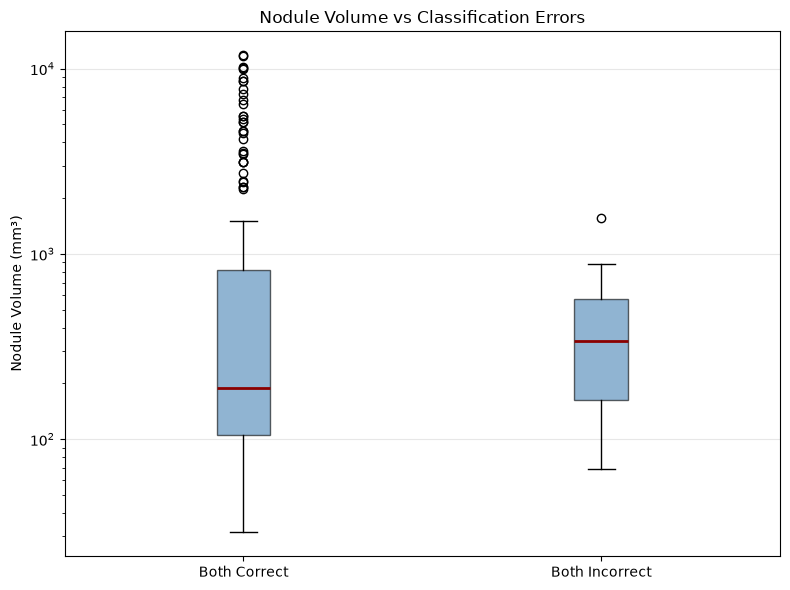

In [31]:
# Add nodule volume to the error analysis
error_analysis["volume_mm3"] = testing_dataset[
    "original_shape_VoxelVolume"
]

# Identify nodules correctly classified by both models
both_models_correct = (
    (~error_analysis["rf_error"]) &
    (~error_analysis["svm_error"])
)

# Select correctly classified nodules
correct_nodules = error_analysis[both_models_correct]

# Select nodules misclassified by both models
incorrect_nodules = error_analysis[
    error_analysis["both_models_wrong"]
]

# Compare volume statistics
print("Correctly classified by both:", len(correct_nodules))
print("Misclassified by both:", len(incorrect_nodules))

print("\nMedian volume of correctly classified nodules:")
print(correct_nodules["volume_mm3"].median())

print("\nMedian volume of incorrectly classified nodules:")
print(incorrect_nodules["volume_mm3"].median())


# Prepare data for visualization
volume_groups = [
    correct_nodules["volume_mm3"],
    incorrect_nodules["volume_mm3"]
]

# Create boxplot
fig, ax = plt.subplots(figsize=(8, 6))

ax.boxplot(
    volume_groups,
    tick_labels=["Both Correct", "Both Incorrect"],
    patch_artist=True,
    boxprops={"facecolor": "steelblue", "alpha": 0.6},
    medianprops={"color": "darkred", "linewidth": 2}
)

ax.set_title("Nodule Volume vs Classification Errors")
ax.set_ylabel("Nodule Volume (mm³)")
ax.set_yscale("log")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save the figure
fig.savefig(
    project_directory / "results" / "volume_vs_classification_errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
# Compare nodule volumes within each malignancy class
for malignancy_label in [0, 1]:

    correct_group = correct_nodules[
        correct_nodules["malignancy_label"] == malignancy_label
    ]

    incorrect_group = incorrect_nodules[
        incorrect_nodules["malignancy_label"] == malignancy_label
    ]

    print(f"\nMalignancy label: {malignancy_label}")

    print("Correctly classified:", len(correct_group))
    print("Incorrectly classified:", len(incorrect_group))

    print("Median volume (correct):",
          round(correct_group["volume_mm3"].median(), 2))

    print("Median volume (incorrect):",
          round(incorrect_group["volume_mm3"].median(), 2))


Malignancy label: 0
Correctly classified: 120
Incorrectly classified: 7
Median volume (correct): 137.88
Median volume (incorrect): 564.19

Malignancy label: 1
Correctly classified: 57
Incorrectly classified: 11
Median volume (correct): 2476.5
Median volume (incorrect): 172.67


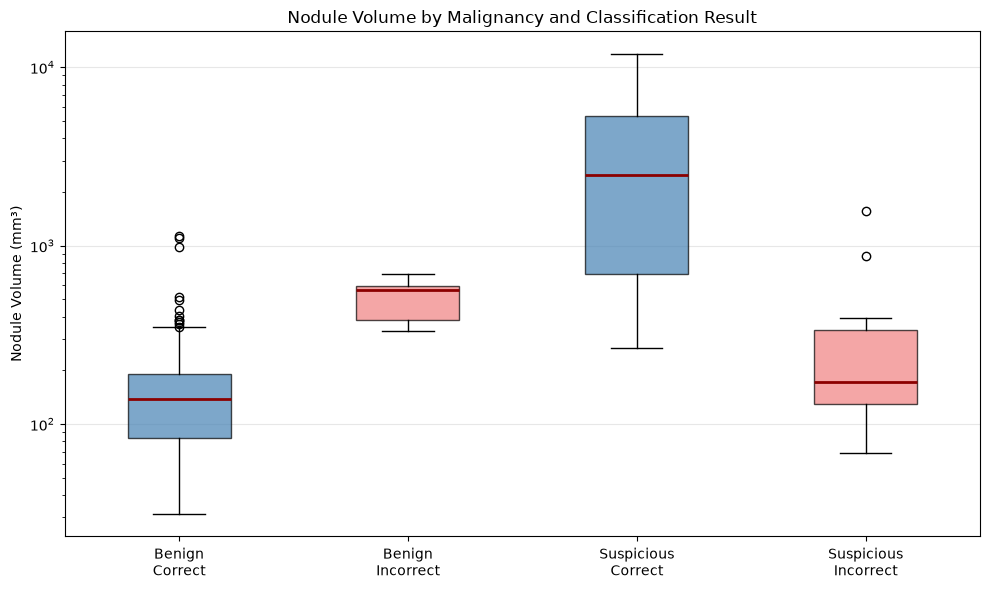

In [33]:
# Separate nodules by malignancy and classification result
benign_correct = correct_nodules[
    correct_nodules["malignancy_label"] == 0
]

benign_incorrect = incorrect_nodules[
    incorrect_nodules["malignancy_label"] == 0
]

suspicious_correct = correct_nodules[
    correct_nodules["malignancy_label"] == 1
]

suspicious_incorrect = incorrect_nodules[
    incorrect_nodules["malignancy_label"] == 1
]


# Prepare volume data for the boxplot
volume_groups = [
    benign_correct["volume_mm3"],
    benign_incorrect["volume_mm3"],
    suspicious_correct["volume_mm3"],
    suspicious_incorrect["volume_mm3"]
]

group_labels = [
    "Benign\nCorrect",
    "Benign\nIncorrect",
    "Suspicious\nCorrect",
    "Suspicious\nIncorrect"
]


# Create boxplot
fig, ax = plt.subplots(figsize=(10, 6))

boxplot = ax.boxplot(
    volume_groups,
    tick_labels=group_labels,
    patch_artist=True,
    medianprops={"color": "darkred", "linewidth": 2}
)

# Assign colors to distinguish the groups
group_colors = ["steelblue", "lightcoral", "steelblue", "lightcoral"]

for box, color in zip(boxplot["boxes"], group_colors):
    box.set_facecolor(color)
    box.set_alpha(0.7)


# Configure figure
ax.set_title("Nodule Volume by Malignancy and Classification Result")
ax.set_ylabel("Nodule Volume (mm³)")
ax.set_yscale("log")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save figure in results
fig.savefig(
    project_directory / "results" / "volume_by_malignancy_and_errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
# Check whether malignancy assessments have a unique mode
def has_ambiguous_malignancy(malignancy_scores):

    most_frequent_scores = malignancy_scores.mode()

    if len(most_frequent_scores) > 1:
        return True

    return False


# Evaluate agreement for each nodule
malignancy_agreement = metadata.groupby(
    ["patient_id", "nodule_id"]
)["Malignancy_value"].apply(has_ambiguous_malignancy)

malignancy_agreement = malignancy_agreement.reset_index(
    name="ambiguous_malignancy"
)


# Add agreement information to the error analysis
agreement_analysis = error_analysis.merge(
    malignancy_agreement,
    on=["patient_id", "nodule_id"],
    how="left",
    validate="one_to_one"
)


# Compare correctly and incorrectly classified nodules
both_correct = agreement_analysis[
    (~agreement_analysis["rf_error"]) &
    (~agreement_analysis["svm_error"])
]

both_incorrect = agreement_analysis[
    agreement_analysis["both_models_wrong"]
]


# Display results
for group_name, group_data in [
    ("Both Correct", both_correct),
    ("Both Incorrect", both_incorrect)
]:

    total_nodules = len(group_data)
    ambiguous_nodules = group_data["ambiguous_malignancy"].sum()

    ambiguous_percentage = ambiguous_nodules / total_nodules * 100

    print(f"\n{group_name}")
    print("Total nodules:", total_nodules)
    print("Nodules with ambiguous mode:", ambiguous_nodules)
    print("Percentage:", round(ambiguous_percentage, 2), "%")


Both Correct
Total nodules: 177
Nodules with ambiguous mode: 34
Percentage: 19.21 %

Both Incorrect
Total nodules: 18
Nodules with ambiguous mode: 4
Percentage: 22.22 %


Original features: 107
Components for 90% variance: 10
Components for 95% variance: 15


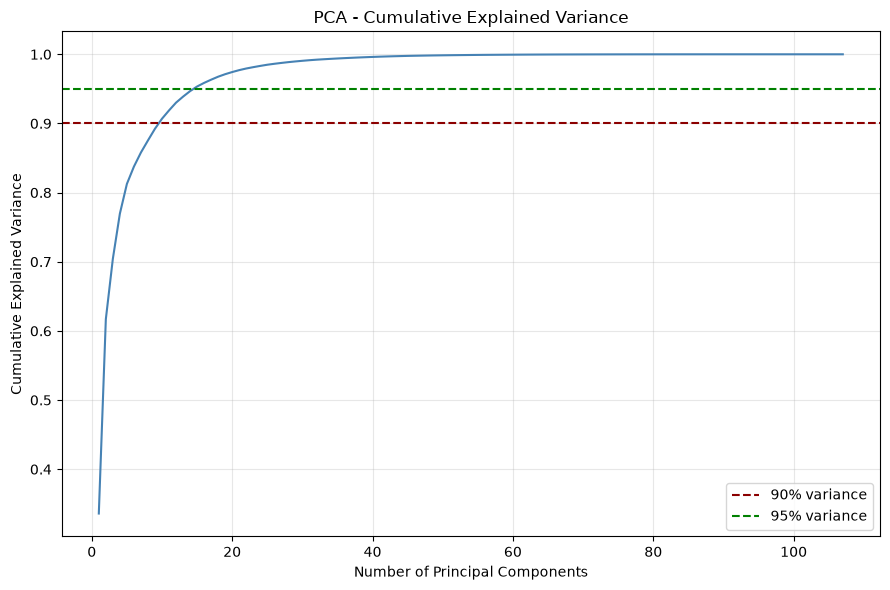

In [35]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Standardize the radiomic features
scaler = StandardScaler()

scaled_training_features = scaler.fit_transform(
    training_features
)

# Apply PCA to all 107 features
pca = PCA()

pca.fit(scaled_training_features)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

# Find the number of components required
components_90 = np.searchsorted(cumulative_variance, 0.90) + 1
components_95 = np.searchsorted(cumulative_variance, 0.95) + 1

print("Original features:", training_features.shape[1])
print("Components for 90% variance:", components_90)
print("Components for 95% variance:", components_95)


# Visualize cumulative explained variance
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    color="steelblue"
)

ax.axhline(0.90, color="darkred", linestyle="--", label="90% variance")
ax.axhline(0.95, color="green", linestyle="--", label="95% variance")

ax.set_title("PCA - Cumulative Explained Variance")
ax.set_xlabel("Number of Principal Components")
ax.set_ylabel("Cumulative Explained Variance")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()

# Save figure
fig.savefig(
    project_directory / "results" / "pca_explained_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

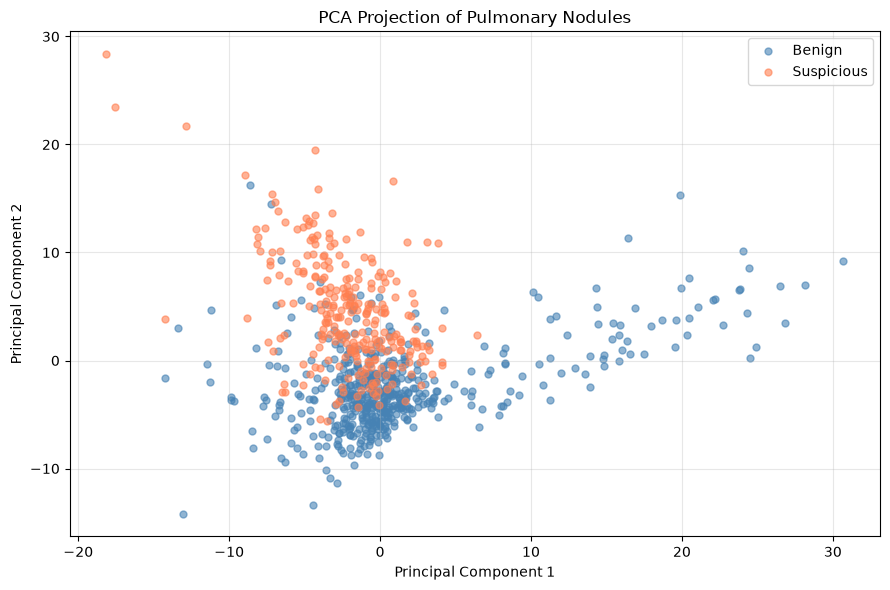

In [36]:
# Transform training data into principal components
principal_components = pca.transform(scaled_training_features)

# Get malignancy labels
malignancy_labels = training_labels.to_numpy()

# Create scatter plot
fig, ax = plt.subplots(figsize=(9, 6))

for malignancy_level in [0, 1]:

    selected_nodules = malignancy_labels == malignancy_level

    if malignancy_level == 0:
        label = "Benign"
        color = "steelblue"
    else:
        label = "Suspicious"
        color = "coral"

    ax.scatter(
        principal_components[selected_nodules, 0],
        principal_components[selected_nodules, 1],
        label=label,
        color=color,
        alpha=0.6,
        s=25
    )

# Configure plot
ax.set_title("PCA Projection of Pulmonary Nodules")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)

plt.tight_layout()

# Save figure
fig.savefig(
    project_directory / "results" / "pca_nodule_projection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Select the first 15 principal components
reduced_training_features = principal_components[:, :components_95]

# Create K-Means with two clusters
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

# Identify clusters without using malignancy labels
cluster_labels = kmeans.fit_predict(reduced_training_features)

# Evaluate the clustering structure
silhouette = silhouette_score(
    reduced_training_features,
    cluster_labels
)

# Compare clusters with the original malignancy labels
adjusted_rand = adjusted_rand_score(
    training_labels,
    cluster_labels
)

print("Silhouette Score:", round(silhouette, 3))
print("Adjusted Rand Index:", round(adjusted_rand, 3))

print("\nNodules per cluster:")

for cluster_number in [0, 1]:
    cluster_count = (cluster_labels == cluster_number).sum()
    print(f"Cluster {cluster_number}: {cluster_count} nodules")

Silhouette Score: 0.302
Adjusted Rand Index: 0.388

Nodules per cluster:
Cluster 0: 207 nodules
Cluster 1: 586 nodules


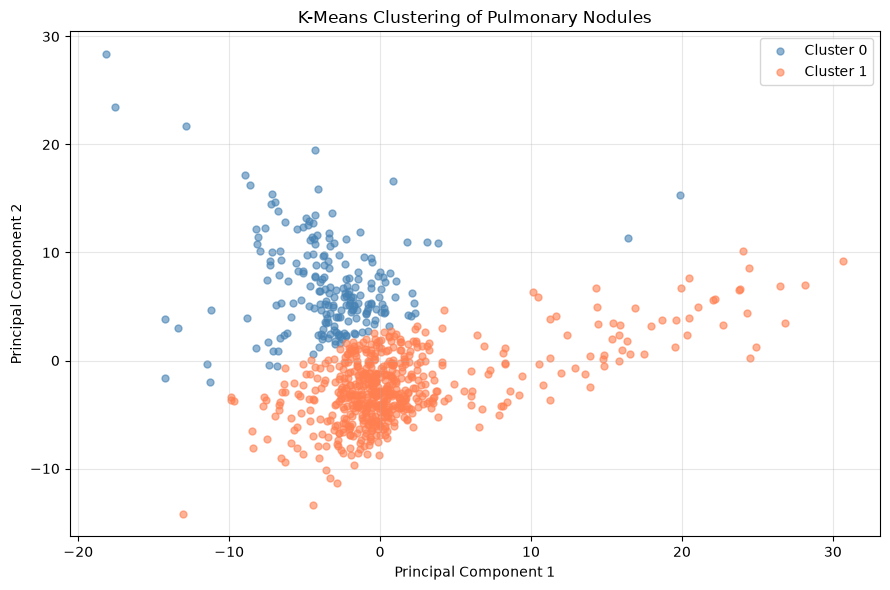

In [38]:
# Create scatter plot for K-Means clusters
fig, ax = plt.subplots(figsize=(9, 6))

cluster_colors = ["steelblue", "coral"]

for cluster_number in [0, 1]:

    selected_nodules = cluster_labels == cluster_number

    ax.scatter(
        principal_components[selected_nodules, 0],
        principal_components[selected_nodules, 1],
        color=cluster_colors[cluster_number],
        label=f"Cluster {cluster_number}",
        alpha=0.6,
        s=25
    )

# Configure plot
ax.set_title("K-Means Clustering of Pulmonary Nodules")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)

plt.tight_layout()

# Save figure
fig.savefig(
    project_directory / "results" / "kmeans_nodule_clusters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [39]:
# Combine cluster assignments with malignancy labels
cluster_analysis = pd.DataFrame({
    "Cluster": cluster_labels,
    "Malignancy": training_labels.to_numpy()
})

# Count benign and suspicious nodules in each cluster
cluster_distribution = pd.crosstab(
    cluster_analysis["Cluster"],
    cluster_analysis["Malignancy"]
)

print("Nodules per cluster and malignancy:")
display(cluster_distribution)

# Calculate percentages within each cluster
cluster_percentages = pd.crosstab(
    cluster_analysis["Cluster"],
    cluster_analysis["Malignancy"],
    normalize="index"
) * 100

print("Malignancy distribution within each cluster (%):")
display(cluster_percentages.round(2))

Nodules per cluster and malignancy:


Malignancy,0,1
Cluster,,
0,39,168
1,480,106


Malignancy distribution within each cluster (%):


Malignancy,0,1
Cluster,,
0,18.84,81.16
1,81.91,18.09


,Clusters,Silhouette Score
0,2,0.302
1,3,0.364
2,4,0.222
3,5,0.240
4,6,0.245


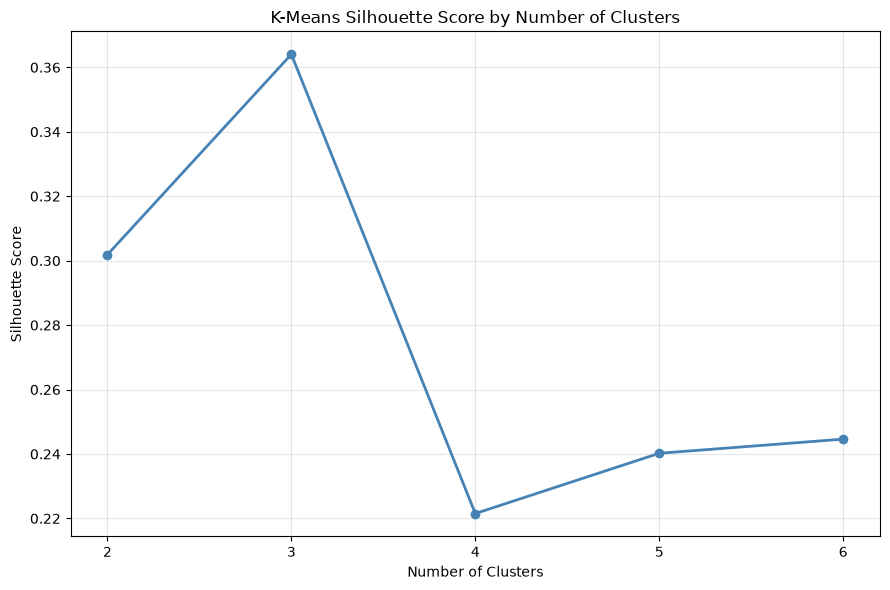

In [40]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import pandas as pd

# Store clustering results
clustering_results = []

# Evaluate different numbers of clusters
for number_of_clusters in range(2, 7):

    # Create K-Means model
    kmeans_model = KMeans(
        n_clusters=number_of_clusters,
        random_state=42,
        n_init=20
    )

    # Assign each nodule to a cluster
    predicted_clusters = kmeans_model.fit_predict(
        reduced_training_features
    )

    # Calculate silhouette score
    silhouette = silhouette_score(
        reduced_training_features,
        predicted_clusters
    )

    # Store results
    clustering_results.append({
        "Clusters": number_of_clusters,
        "Silhouette Score": silhouette
    })

# Create results table
clustering_table = pd.DataFrame(clustering_results)

display(clustering_table.round(3))


# Visualize silhouette scores
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    clustering_table["Clusters"],
    clustering_table["Silhouette Score"],
    marker="o",
    color="steelblue",
    linewidth=2
)

ax.set_title("K-Means Silhouette Score by Number of Clusters")
ax.set_xlabel("Number of Clusters")
ax.set_ylabel("Silhouette Score")
ax.set_xticks(range(2, 7))
ax.grid(alpha=0.3)

plt.tight_layout()

# Save plot in results
fig.savefig(
    project_directory / "results" / "kmeans_silhouette_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
# Create K-Means with three clusters
three_cluster_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

# Assign nodules to clusters
three_cluster_labels = three_cluster_model.fit_predict(
    reduced_training_features
)

# Compare clusters with malignancy labels
three_cluster_distribution = pd.crosstab(
    three_cluster_labels,
    training_labels.to_numpy(),
    normalize="index"
) * 100

print("Malignancy distribution per cluster (%):")
display(three_cluster_distribution.round(2))

# Evaluate agreement with malignancy labels
three_cluster_ari = adjusted_rand_score(
    training_labels,
    three_cluster_labels
)

print("Adjusted Rand Index:", round(three_cluster_ari, 3))

Malignancy distribution per cluster (%):


col_0,0,1
row_0,,
0,16.75,83.25
1,100.00,0.00
2,79.59,20.41


Adjusted Rand Index: 0.288


In [42]:
# Count nodules in each cluster
cluster_counts = pd.Series(three_cluster_labels).value_counts()

# Sort clusters by their identifier
cluster_counts = cluster_counts.sort_index()

print("Number of nodules per cluster:")
print(cluster_counts)

Number of nodules per cluster:
0    197
1     57
2    539
Name: count, dtype: int64


In [43]:
from sklearn.model_selection import StratifiedGroupKFold

# Keep the original testing dataset unchanged
final_testing_dataset = testing_dataset.copy()

# Prepare the remaining 793 nodules
development_dataset = training_dataset.copy()

# Create a patient-based split for training and validation
validation_splitter = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

# Generate the training and validation indices
split_indices = validation_splitter.split(
    development_dataset[feature_columns],
    development_dataset["malignancy_label"],
    groups=development_dataset["patient_id"]
)

training_indices, validation_indices = next(split_indices)

# Create the three datasets
final_training_dataset = development_dataset.iloc[
    training_indices
].copy()

validation_dataset = development_dataset.iloc[
    validation_indices
].copy()

# Display dataset sizes
print("Training nodules:", len(final_training_dataset))
print("Validation nodules:", len(validation_dataset))
print("Testing nodules:", len(final_testing_dataset))

Training nodules: 595
Validation nodules: 198
Testing nodules: 200


In [44]:
# Identify patients in each dataset
train_patients = set(final_training_dataset["patient_id"])
validation_patients = set(validation_dataset["patient_id"])
test_patients = set(final_testing_dataset["patient_id"])

# Check patient overlap
train_validation_overlap = train_patients.intersection(validation_patients)
train_test_overlap = train_patients.intersection(test_patients)
validation_test_overlap = validation_patients.intersection(test_patients)

print("Train / Validation shared patients:", len(train_validation_overlap))
print("Train / Test shared patients:", len(train_test_overlap))
print("Validation / Test shared patients:", len(validation_test_overlap))

# Display class distribution
for dataset_name, dataset in [
    ("Training", final_training_dataset),
    ("Validation", validation_dataset),
    ("Testing", final_testing_dataset)
]:

    print(f"\n{dataset_name}")
    print(dataset["malignancy_label"].value_counts())

Train / Validation shared patients: 0
Train / Test shared patients: 0
Validation / Test shared patients: 0

Training
malignancy_label
0    390
1    205
Name: count, dtype: int64

Validation
malignancy_label
0    129
1     69
Name: count, dtype: int64

Testing
malignancy_label
0    131
1     69
Name: count, dtype: int64


In [45]:
# Save datasets to the results directory
final_training_dataset.to_csv(
    project_directory / "results" / "training_dataset.csv",
    index=False
)

validation_dataset.to_csv(
    project_directory / "results" / "validation_dataset.csv",
    index=False
)

final_testing_dataset.to_csv(
    project_directory / "results" / "testing_dataset.csv",
    index=False
)

In [46]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Prepare training and validation data
X_train = final_training_dataset[feature_columns]
y_train = final_training_dataset["malignancy_label"]

X_validation = validation_dataset[feature_columns]
y_validation = validation_dataset["malignancy_label"]


# Create fresh classifiers
validation_random_forest = clone(random_forest)
validation_svm = clone(svm_classifier)

models = {
    "Random Forest": validation_random_forest,
    "SVM": validation_svm
}

validation_results_table = []

# Train and evaluate both models
for model_name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_validation)

    model_results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_validation, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_validation, predictions),
        "Precision": precision_score(y_validation, predictions),
        "Recall": recall_score(y_validation, predictions),
        "F1": f1_score(y_validation, predictions)
    }

    validation_results_table.append(model_results)


# Display comparison
validation_comparison = pd.DataFrame(validation_results_table)

display(validation_comparison.round(3))

# Save results
validation_comparison.to_csv(
    project_directory / "results" / "model_validation_comparison.csv",
    index=False
)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1
0,Random Forest,0.833,0.845,0.709,0.884,0.787
1,SVM,0.818,0.837,0.681,0.899,0.775


In [47]:
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier

# Define the hyperparameters to evaluate
rf_parameters = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 3, 5]
}

# Configure patient-based cross-validation
rf_cross_validation = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

# Create a new Random Forest
rf_base_model = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=1
)

# Configure hyperparameter optimization
rf_grid_search = GridSearchCV(
    estimator=rf_base_model,
    param_grid=rf_parameters,
    scoring="f1",
    cv=rf_cross_validation,
    n_jobs=-1,
    refit=True
)

# Optimize using only the training set
rf_grid_search.fit(
    X_train,
    y_train,
    groups=final_training_dataset["patient_id"]
)

# Display results
print("Best Random Forest parameters:")
print(rf_grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(rf_grid_search.best_score_, 3))

Best Random Forest parameters:
{'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 100}

Best cross-validation F1-score:
0.851


In [48]:
# Compare original and optimized Random Forest
rf_models = {
    "Original Random Forest": validation_random_forest,
    "Optimized Random Forest": rf_grid_search.best_estimator_
}

rf_comparison_results = []

for model_name, model in rf_models.items():

    predictions = model.predict(X_validation)

    model_results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_validation, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_validation, predictions),
        "Precision": precision_score(y_validation, predictions),
        "Recall": recall_score(y_validation, predictions),
        "F1": f1_score(y_validation, predictions)
    }

    rf_comparison_results.append(model_results)


# Display comparison
rf_comparison_table = pd.DataFrame(rf_comparison_results)

display(rf_comparison_table.round(3))


# Save results
rf_comparison_table.to_csv(
    project_directory / "results" / "rf_optimization_comparison.csv",
    index=False
)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1
0,Original Random Forest,0.833,0.845,0.709,0.884,0.787
1,Optimized Random Forest,0.828,0.841,0.701,0.884,0.782


In [49]:
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.base import clone

# Define SVM hyperparameters
svm_parameters = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.001, 0.01, 0.1]
}

# Configure patient-based cross-validation
svm_cross_validation = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

# Configure hyperparameter search
new_svm_grid_search = GridSearchCV(
    estimator=clone(svm_classifier),
    param_grid=svm_parameters,
    scoring="f1",
    cv=svm_cross_validation,
    n_jobs=-1,
    refit=True
)

# Optimize using training data only
new_svm_grid_search.fit(
    X_train,
    y_train,
    groups=final_training_dataset["patient_id"]
)

# Display results
print("Best SVM parameters:")
print(new_svm_grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(new_svm_grid_search.best_score_, 3))

Best SVM parameters:
{'svm__C': 1, 'svm__gamma': 0.01}

Best cross-validation F1-score:
0.833


In [50]:
# Compare original and optimized SVM
svm_models = {
    "Original SVM": validation_svm,
    "Optimized SVM": new_svm_grid_search.best_estimator_
}

svm_comparison_results = []

for model_name, model in svm_models.items():

    # Predict using the validation dataset
    predictions = model.predict(X_validation)

    # Calculate performance metrics
    model_results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_validation, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_validation, predictions),
        "Precision": precision_score(y_validation, predictions),
        "Recall": recall_score(y_validation, predictions),
        "F1": f1_score(y_validation, predictions)
    }

    svm_comparison_results.append(model_results)


# Display comparison
svm_comparison_table = pd.DataFrame(svm_comparison_results)

display(svm_comparison_table.round(3))


# Save results
svm_comparison_table.to_csv(
    project_directory / "results" / "svm_optimization_comparison.csv",
    index=False
)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1
0,Original SVM,0.818,0.837,0.681,0.899,0.775
1,Optimized SVM,0.818,0.837,0.681,0.899,0.775


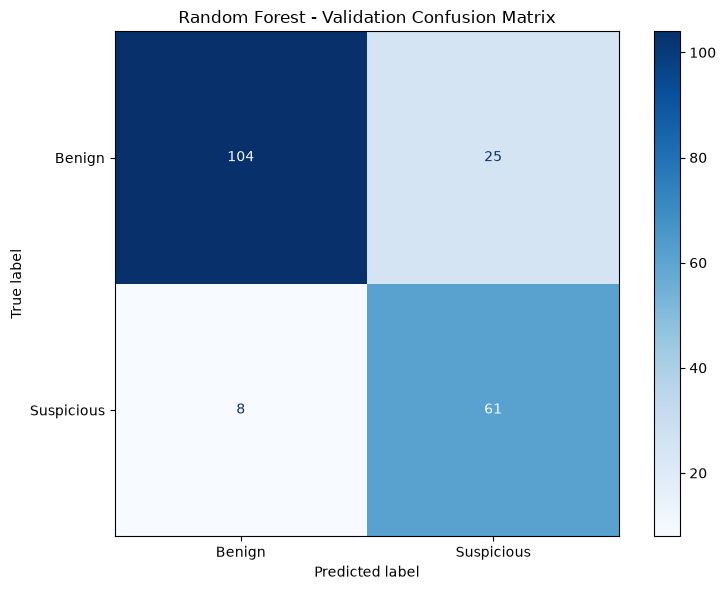

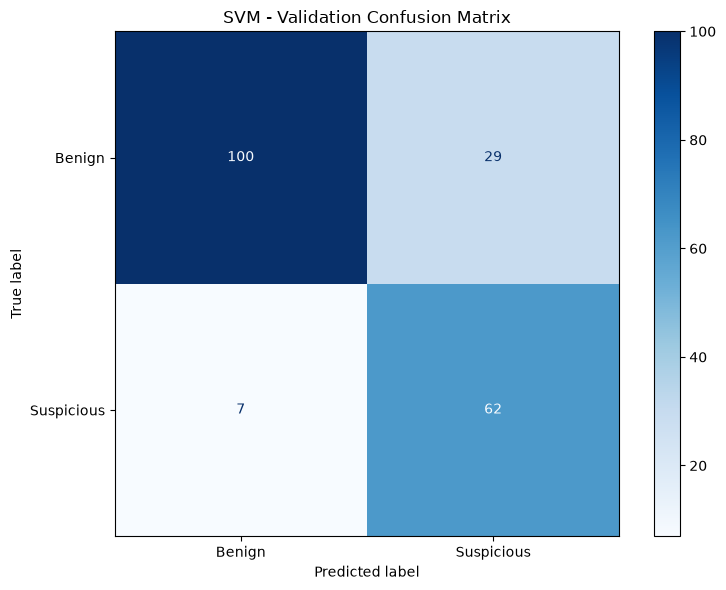

In [51]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Models selected for comparison
selected_models = {
    "Random Forest": validation_random_forest,
    "SVM": validation_svm
}

# Generate confusion matrices
for model_name, model in selected_models.items():

    predictions = model.predict(X_validation)

    fig, ax = plt.subplots(figsize=(8, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_validation,
        predictions,
        display_labels=["Benign", "Suspicious"],
        cmap="Blues",
        ax=ax
    )

    ax.set_title(f"{model_name} - Validation Confusion Matrix")

    plt.tight_layout()

    # Save each figure
    file_name = model_name.lower().replace(" ", "_")
    output_path = (
        project_directory / "results" /
        f"{file_name}_validation_confusion_matrix.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

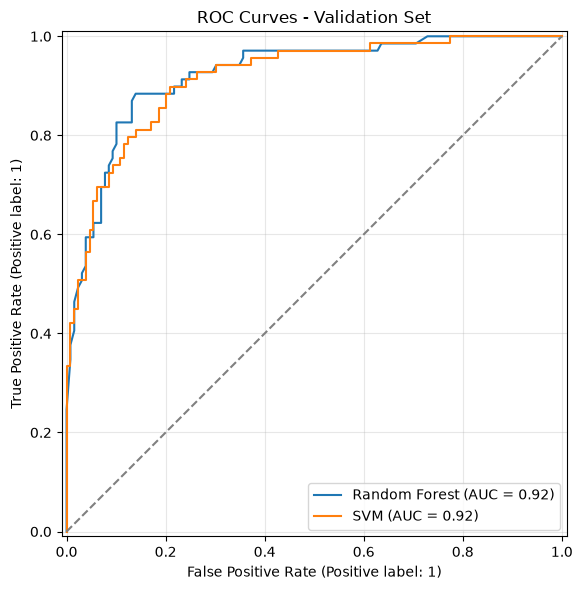

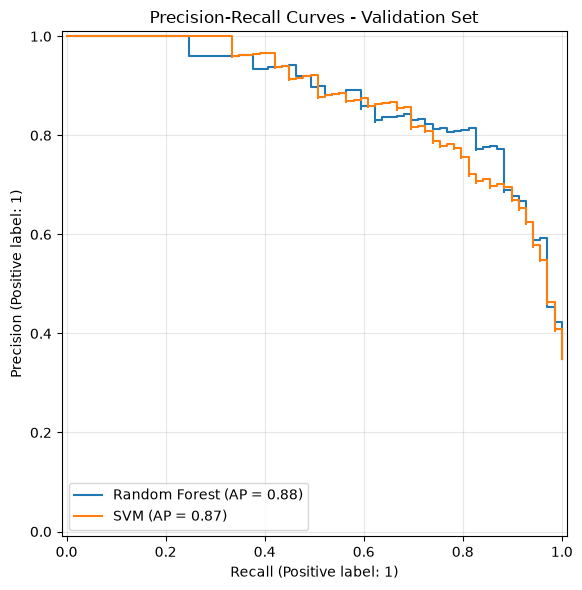

In [52]:
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

# Obtain prediction scores from both classifiers
rf_scores = validation_random_forest.predict_proba(
    X_validation
)[:, 1]

svm_scores = validation_svm.decision_function(
    X_validation
)

# Store model scores
model_scores = {
    "Random Forest": rf_scores,
    "SVM": svm_scores
}


# Create ROC comparison
fig, ax = plt.subplots(figsize=(8, 6))

for model_name, scores in model_scores.items():

    RocCurveDisplay.from_predictions(
        y_validation,
        scores,
        name=model_name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", color="gray")

ax.set_title("ROC Curves - Validation Set")
ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig(
    project_directory / "results" / "validation_roc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Create Precision-Recall comparison
fig, ax = plt.subplots(figsize=(8, 6))

for model_name, scores in model_scores.items():

    PrecisionRecallDisplay.from_predictions(
        y_validation,
        scores,
        name=model_name,
        ax=ax
    )

ax.set_title("Precision-Recall Curves - Validation Set")
ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig(
    project_directory / "results" / "validation_precision_recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [53]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Obtain predictions from our selected Random Forest
validation_predictions = validation_random_forest.predict(X_validation)

validation_probabilities = validation_random_forest.predict_proba(
    X_validation
)[:, 1]

true_labels = y_validation.to_numpy()
patient_ids = validation_dataset["patient_id"].to_numpy()

# Identify the patients in the validation dataset
unique_patients = np.unique(patient_ids)

# Store the nodule positions belonging to each patient
patient_positions = {}

for patient_id in unique_patients:
    patient_positions[patient_id] = np.where(
        patient_ids == patient_id
    )[0]


# Configure Bootstrap
number_of_iterations = 1000
random_generator = np.random.default_rng(42)

bootstrap_results = []

for iteration in range(number_of_iterations):

    # Sample patients with replacement
    sampled_patients = random_generator.choice(
        unique_patients,
        size=len(unique_patients),
        replace=True
    )

    # Collect all nodules from the sampled patients
    sampled_positions = []

    for patient_id in sampled_patients:
        sampled_positions.extend(patient_positions[patient_id])

    # Get labels, predictions and probabilities
    sampled_labels = true_labels[sampled_positions]
    sampled_predictions = validation_predictions[sampled_positions]
    sampled_probabilities = validation_probabilities[sampled_positions]

    # ROC-AUC requires both classes
    if len(np.unique(sampled_labels)) < 2:
        continue

    # Calculate performance metrics
    iteration_results = {
        "Accuracy": accuracy_score(
            sampled_labels, sampled_predictions
        ),
        "Precision": precision_score(
            sampled_labels, sampled_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            sampled_labels, sampled_predictions
        ),
        "F1": f1_score(
            sampled_labels, sampled_predictions
        ),
        "ROC-AUC": roc_auc_score(
            sampled_labels, sampled_probabilities
        )
    }

    bootstrap_results.append(iteration_results)


# Convert results into a DataFrame
bootstrap_table = pd.DataFrame(bootstrap_results)

# Calculate confidence intervals
confidence_intervals = []

original_scores = {
    "Accuracy": accuracy_score(true_labels, validation_predictions),
    "Precision": precision_score(true_labels, validation_predictions),
    "Recall": recall_score(true_labels, validation_predictions),
    "F1": f1_score(true_labels, validation_predictions),
    "ROC-AUC": roc_auc_score(true_labels, validation_probabilities)
}

for metric_name in original_scores:

    lower_limit = bootstrap_table[metric_name].quantile(0.025)
    upper_limit = bootstrap_table[metric_name].quantile(0.975)

    confidence_intervals.append({
        "Metric": metric_name,
        "Score": original_scores[metric_name],
        "CI Lower": lower_limit,
        "CI Upper": upper_limit
    })

# Display results
confidence_table = pd.DataFrame(confidence_intervals)

display(confidence_table.round(3))

print("Valid Bootstrap iterations:", len(bootstrap_table))

# Save results
confidence_table.to_csv(
    project_directory / "results" / "rf_bootstrap_confidence_intervals.csv",
    index=False
)

,Metric,Score,CI Lower,CI Upper
0,Accuracy,0.833,0.778,0.882
1,Precision,0.709,0.616,0.795
2,Recall,0.884,0.803,0.952
3,F1,0.787,0.717,0.848
4,ROC-AUC,0.923,0.885,0.956


Valid Bootstrap iterations: 1000


In [54]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Obtain SVM predictions and decision scores
svm_validation_predictions = validation_svm.predict(X_validation)

svm_validation_scores = validation_svm.decision_function(
    X_validation
)


# Define the metrics to evaluate
def calculate_metrics(true_values, predicted_values, scores):

    results = {
        "Accuracy": accuracy_score(true_values, predicted_values),
        "Precision": precision_score(
            true_values, predicted_values, zero_division=0
        ),
        "Recall": recall_score(true_values, predicted_values),
        "F1": f1_score(true_values, predicted_values),
        "ROC-AUC": roc_auc_score(true_values, scores)
    }

    return results


# Calculate the original performance of both models
original_rf_scores = calculate_metrics(
    true_labels,
    validation_predictions,
    validation_probabilities
)

original_svm_scores = calculate_metrics(
    true_labels,
    svm_validation_predictions,
    svm_validation_scores
)


# Configure paired Bootstrap
random_generator = np.random.default_rng(42)
number_of_iterations = 1000

paired_bootstrap_results = []

for iteration in range(number_of_iterations):

    # Sample validation patients with replacement
    sampled_patients = random_generator.choice(
        unique_patients,
        size=len(unique_patients),
        replace=True
    )

    # Include all nodules belonging to each sampled patient
    sampled_positions = []

    for patient_id in sampled_patients:
        sampled_positions.extend(patient_positions[patient_id])

    sampled_labels = true_labels[sampled_positions]

    # ROC-AUC requires both classes
    if len(np.unique(sampled_labels)) < 2:
        continue

    # Calculate Random Forest metrics
    rf_results = calculate_metrics(
        sampled_labels,
        validation_predictions[sampled_positions],
        validation_probabilities[sampled_positions]
    )

    # Calculate SVM metrics using the same nodules
    svm_results = calculate_metrics(
        sampled_labels,
        svm_validation_predictions[sampled_positions],
        svm_validation_scores[sampled_positions]
    )

    # Store paired results
    iteration_results = {}

    for metric_name in rf_results:

        iteration_results["RF " + metric_name] = rf_results[metric_name]
        iteration_results["SVM " + metric_name] = svm_results[metric_name]

        iteration_results["Difference " + metric_name] = (
            rf_results[metric_name] - svm_results[metric_name]
        )

    paired_bootstrap_results.append(iteration_results)


# Calculate confidence intervals
paired_bootstrap_table = pd.DataFrame(paired_bootstrap_results)

comparison_summary = []

for metric_name in original_rf_scores:

    rf_values = paired_bootstrap_table["RF " + metric_name]
    svm_values = paired_bootstrap_table["SVM " + metric_name]
    difference_values = paired_bootstrap_table["Difference " + metric_name]

    comparison_summary.append({
        "Metric": metric_name,
        "RF Score": original_rf_scores[metric_name],
        "RF CI Lower": rf_values.quantile(0.025),
        "RF CI Upper": rf_values.quantile(0.975),
        "SVM Score": original_svm_scores[metric_name],
        "SVM CI Lower": svm_values.quantile(0.025),
        "SVM CI Upper": svm_values.quantile(0.975),
        "Difference": (
            original_rf_scores[metric_name]
            - original_svm_scores[metric_name]
        ),
        "Difference CI Lower": difference_values.quantile(0.025),
        "Difference CI Upper": difference_values.quantile(0.975)
    })


# Display comparison
bootstrap_comparison_table = pd.DataFrame(comparison_summary)

display(bootstrap_comparison_table.round(3))

print("Valid Bootstrap iterations:", len(paired_bootstrap_table))


# Save results
bootstrap_comparison_table.to_csv(
    project_directory / "results" / "rf_svm_bootstrap_comparison.csv",
    index=False
)

,Metric,RF Score,RF CI Lower,RF CI Upper,SVM Score,SVM CI Lower,SVM CI Upper,Difference,Difference CI Lower,Difference CI Upper
0,Accuracy,0.833,0.778,0.882,0.818,0.765,0.867,0.015,-0.028,0.058
1,Precision,0.709,0.616,0.795,0.681,0.577,0.777,0.028,-0.029,0.092
2,Recall,0.884,0.803,0.952,0.899,0.824,0.966,-0.014,-0.078,0.048
3,F1,0.787,0.717,0.848,0.775,0.695,0.840,0.012,-0.039,0.063
4,ROC-AUC,0.923,0.885,0.956,0.916,0.874,0.952,0.008,-0.006,0.022


Valid Bootstrap iterations: 1000


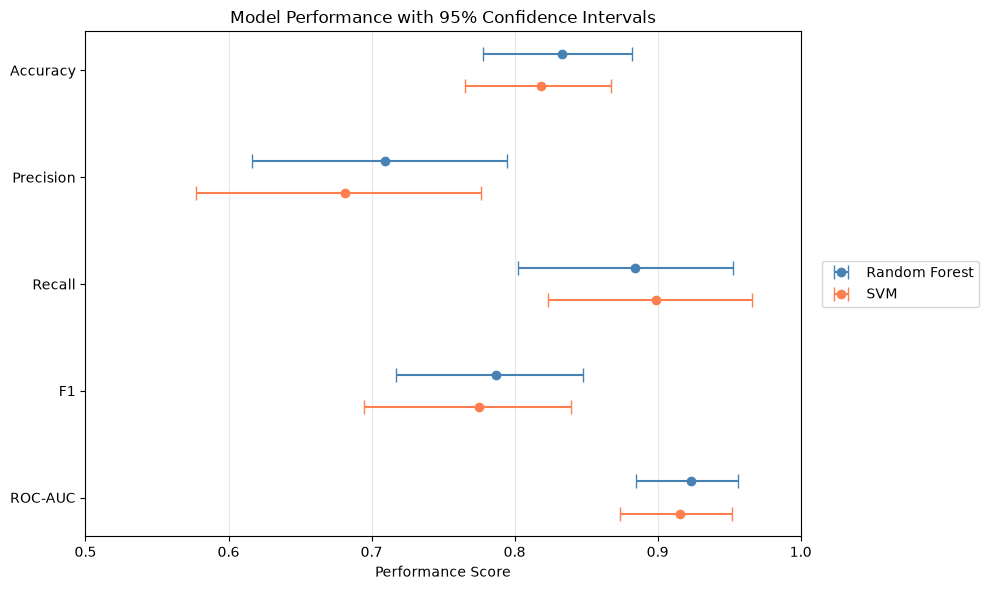

In [55]:
import numpy as np
import matplotlib.pyplot as plt

# Get the metrics from the Bootstrap comparison
metric_names = bootstrap_comparison_table["Metric"]

rf_scores = bootstrap_comparison_table["RF Score"]
rf_lower = bootstrap_comparison_table["RF CI Lower"]
rf_upper = bootstrap_comparison_table["RF CI Upper"]

svm_scores = bootstrap_comparison_table["SVM Score"]
svm_lower = bootstrap_comparison_table["SVM CI Lower"]
svm_upper = bootstrap_comparison_table["SVM CI Upper"]


# Calculate the distance between scores and confidence limits
rf_errors = [
    rf_scores - rf_lower,
    rf_upper - rf_scores
]

svm_errors = [
    svm_scores - svm_lower,
    svm_upper - svm_scores
]


# Configure positions for each classifier
positions = np.arange(len(metric_names))
offset = 0.15

# Create comparison figure
fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(
    rf_scores,
    positions - offset,
    xerr=rf_errors,
    fmt="o",
    capsize=5,
    color="steelblue",
    label="Random Forest"
)

ax.errorbar(
    svm_scores,
    positions + offset,
    xerr=svm_errors,
    fmt="o",
    capsize=5,
    color="coral",
    label="SVM"
)

# Configure figure
ax.set_yticks(positions)
ax.set_yticklabels(metric_names)
ax.invert_yaxis()

ax.set_xlim(0.5, 1.0)
ax.set_xlabel("Performance Score")
ax.set_title("Model Performance with 95% Confidence Intervals")

ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

# Save figure
fig.savefig(
    project_directory / "results" / "model_confidence_intervals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

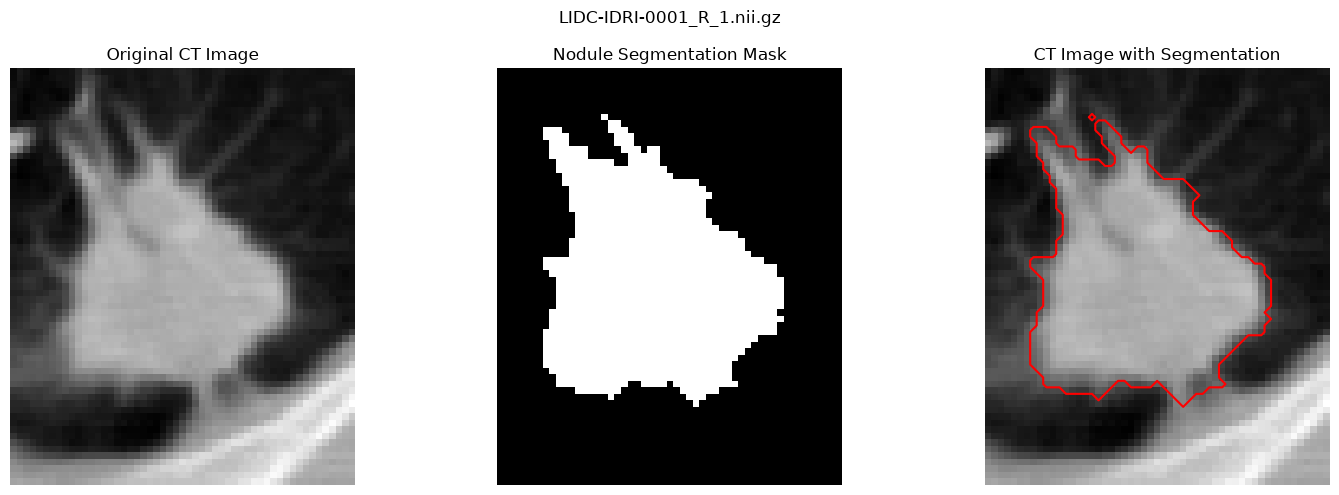

In [56]:
import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt

# Select one nodule from the dataset
image_file = sorted(image_directory.glob("*.nii.gz"))[0]
mask_file = mask_directory / image_file.name

# Load the CT image and its segmentation mask
ct_image = sitk.ReadImage(str(image_file))
nodule_mask = sitk.ReadImage(str(mask_file))

# Convert images to NumPy arrays
ct_array = sitk.GetArrayFromImage(ct_image)
mask_array = sitk.GetArrayFromImage(nodule_mask)

# Find the slice containing the largest mask area
mask_areas = (mask_array > 0).sum(axis=(1, 2))
slice_index = np.argmax(mask_areas)

ct_slice = ct_array[slice_index]
mask_slice = mask_array[slice_index] > 0

# Create visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(ct_slice, cmap="gray")
axes[0].set_title("Original CT Image")

axes[1].imshow(mask_slice, cmap="gray")
axes[1].set_title("Nodule Segmentation Mask")

axes[2].imshow(ct_slice, cmap="gray")
axes[2].contour(mask_slice, colors="red", linewidths=1.5)
axes[2].set_title("CT Image with Segmentation")

for ax in axes:
    ax.axis("off")

fig.suptitle(image_file.name, fontsize=12)

plt.tight_layout()

# Save visualization
fig.savefig(
    project_directory / "results" / "ct_nodule_segmentation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

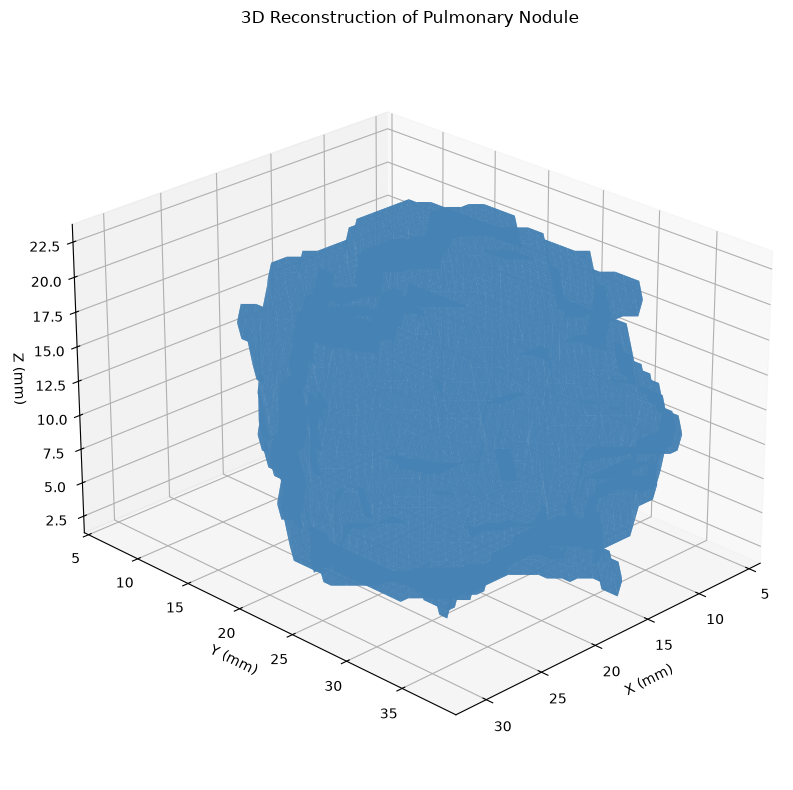

In [57]:
from skimage.measure import marching_cubes
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import matplotlib.pyplot as plt
import numpy as np

# Get voxel spacing in Z, Y, X order
voxel_spacing = nodule_mask.GetSpacing()[::-1]

# Extract the 3D surface from the segmentation mask
vertices, faces, normals, values = marching_cubes(
    mask_array > 0,
    level=0.5,
    spacing=voxel_spacing
)

# Convert vertex coordinates from Z,Y,X to X,Y,Z
vertices_xyz = vertices[:, [2, 1, 0]]

# Build the triangular surface
nodule_surface = Poly3DCollection(
    vertices_xyz[faces],
    alpha=0.85
)

nodule_surface.set_facecolor("steelblue")
nodule_surface.set_edgecolor("none")

# Create 3D figure
fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(111, projection="3d")

ax.add_collection3d(nodule_surface)

# Set axis limits based on the nodule dimensions
minimum_coordinates = vertices_xyz.min(axis=0)
maximum_coordinates = vertices_xyz.max(axis=0)

ax.set_xlim(minimum_coordinates[0], maximum_coordinates[0])
ax.set_ylim(minimum_coordinates[1], maximum_coordinates[1])
ax.set_zlim(minimum_coordinates[2], maximum_coordinates[2])

# Preserve physical proportions
nodule_dimensions = maximum_coordinates - minimum_coordinates
ax.set_box_aspect(nodule_dimensions)

# Configure visualization
ax.set_title("3D Reconstruction of Pulmonary Nodule")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_zlabel("Z (mm)")

ax.view_init(elev=25, azim=45)

plt.tight_layout()

# Save figure
fig.savefig(
    project_directory / "results" / "nodule_3d_reconstruction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

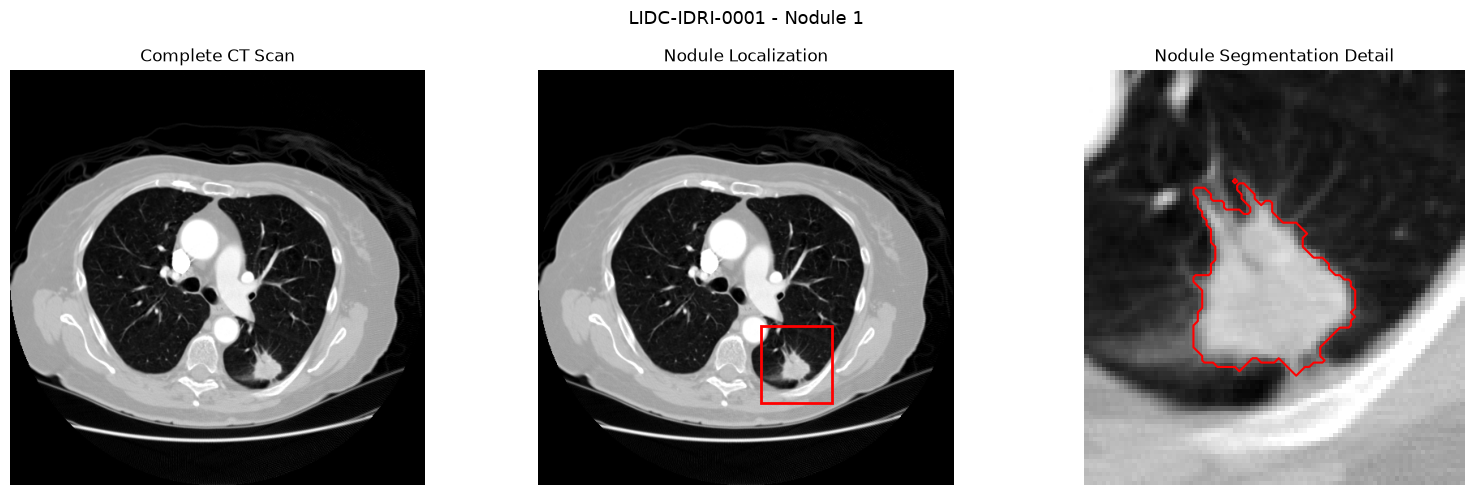

CT dimensions: (512, 512, 133)
Selected slice: 89
Saved to: /Users/omargutierrez/Luna Dataset Project/results/ct_full_scan_nodule_localization.png


In [58]:
import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Rectangle

# Define CT image and mask directories
ct_directory = dataset_directory / "CT" / "image"
ct_mask_directory = dataset_directory / "CT" / "nodule_mask"

# Select patient and nodule
patient_id = "LIDC-IDRI-0001"
nodule_id = 1

ct_path = ct_directory / f"{patient_id}.nii.gz"
mask_path = ct_mask_directory / f"{patient_id}_R_{nodule_id}.nii.gz"

# Load complete CT and nodule mask
ct_volume = sitk.ReadImage(str(ct_path))
mask_volume = sitk.ReadImage(str(mask_path))

# Check that both images have matching geometry
same_geometry = (
    ct_volume.GetSize() == mask_volume.GetSize()
    and np.allclose(ct_volume.GetSpacing(), mask_volume.GetSpacing())
    and np.allclose(ct_volume.GetOrigin(), mask_volume.GetOrigin())
    and np.allclose(ct_volume.GetDirection(), mask_volume.GetDirection())
)

if not same_geometry:
    print("Aligning the mask with the CT volume")

    mask_volume = sitk.Resample(
        mask_volume,
        ct_volume,
        sitk.Transform(),
        sitk.sitkNearestNeighbor,
        0,
        mask_volume.GetPixelID()
    )

# Convert volumes to NumPy arrays
ct_array = sitk.GetArrayFromImage(ct_volume)
mask_array = sitk.GetArrayFromImage(mask_volume) > 0

if not mask_array.any():
    raise ValueError("The nodule mask is empty or not aligned with the CT")

# Find the slice with the largest nodule area
mask_areas = mask_array.sum(axis=(1, 2))
slice_index = int(np.argmax(mask_areas))

ct_slice = ct_array[slice_index]
mask_slice = mask_array[slice_index]

# Identify the nodule boundaries
rows, columns = np.where(mask_slice)

margin = 25

x_min = max(0, columns.min() - margin)
x_max = min(ct_slice.shape[1], columns.max() + margin + 1)

y_min = max(0, rows.min() - margin)
y_max = min(ct_slice.shape[0], rows.max() + margin + 1)

# Extract the enlarged region
ct_detail = ct_slice[y_min:y_max, x_min:x_max]
mask_detail = mask_slice[y_min:y_max, x_min:x_max]

# Create figure
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Complete CT
axes[0].imshow(ct_slice, cmap="gray", vmin=-1000, vmax=400)
axes[0].set_title("Complete CT Scan")

# CT with nodule localization
axes[1].imshow(ct_slice, cmap="gray", vmin=-1000, vmax=400)

nodule_rectangle = Rectangle(
    (x_min, y_min),
    x_max - x_min,
    y_max - y_min,
    edgecolor="red",
    facecolor="none",
    linewidth=2
)

axes[1].add_patch(nodule_rectangle)
axes[1].set_title("Nodule Localization")

# Enlarged nodule with segmentation
axes[2].imshow(ct_detail, cmap="gray", vmin=-1000, vmax=400)

axes[2].contour(
    mask_detail,
    levels=[0.5],
    colors="red",
    linewidths=1.5
)

axes[2].set_title("Nodule Segmentation Detail")

# Configure figure
for ax in axes:
    ax.axis("off")

fig.suptitle(
    f"{patient_id} - Nodule {nodule_id}",
    fontsize=13
)

plt.tight_layout()

# Save figure
output_path = (
    project_directory / "results" /
    "ct_full_scan_nodule_localization.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("CT dimensions:", ct_volume.GetSize())
print("Selected slice:", slice_index)
print("Saved to:", output_path)

Random Forest - Final Testing Evaluation
Testing samples: 200

Accuracy:          0.900
Balanced Accuracy: 0.886
Precision:         0.866
Recall:            0.841
F1-score:          0.853
ROC-AUC:           0.933

Classification Report:
              precision    recall  f1-score   support

      Benign       0.92      0.93      0.92       131
  Suspicious       0.87      0.84      0.85        69

    accuracy                           0.90       200
   macro avg       0.89      0.89      0.89       200
weighted avg       0.90      0.90      0.90       200



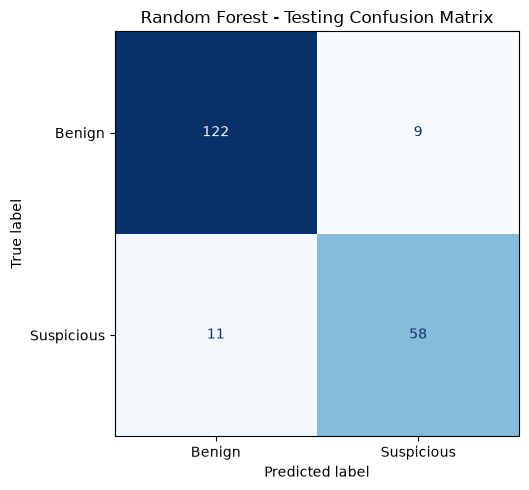

In [59]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Prepare the testing dataset
X_test = final_testing_dataset[feature_columns]
y_test = final_testing_dataset["malignancy_label"]

# Use the already trained Random Forest
test_predictions = validation_random_forest.predict(X_test)
test_probabilities = validation_random_forest.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, test_predictions)
test_balanced_accuracy = balanced_accuracy_score(y_test, test_predictions)
test_precision = precision_score(y_test, test_predictions)
test_recall = recall_score(y_test, test_predictions)
test_f1 = f1_score(y_test, test_predictions)
test_auc = roc_auc_score(y_test, test_probabilities)

print("Random Forest - Final Testing Evaluation")
print("Testing samples:", len(X_test))
print()
print(f"Accuracy:          {test_accuracy:.3f}")
print(f"Balanced Accuracy: {test_balanced_accuracy:.3f}")
print(f"Precision:         {test_precision:.3f}")
print(f"Recall:            {test_recall:.3f}")
print(f"F1-score:          {test_f1:.3f}")
print(f"ROC-AUC:           {test_auc:.3f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["Benign", "Suspicious"]
    )
)

# Generate confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Benign", "Suspicious"],
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=ax
)

ax.set_title("Random Forest - Testing Confusion Matrix")

plt.tight_layout()

# Save the figure
output_path = (
    project_directory / "results" /
    "random_forest_testing_confusion_matrix.png"
)

fig.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()

Random Forest - Validation vs Testing

Accuracy             Validation: 0.833 | Testing: 0.900
Balanced Accuracy    Validation: 0.845 | Testing: 0.886
Precision            Validation: 0.709 | Testing: 0.866
Recall               Validation: 0.884 | Testing: 0.841
F1-score             Validation: 0.787 | Testing: 0.853
ROC-AUC              Validation: 0.923 | Testing: 0.933


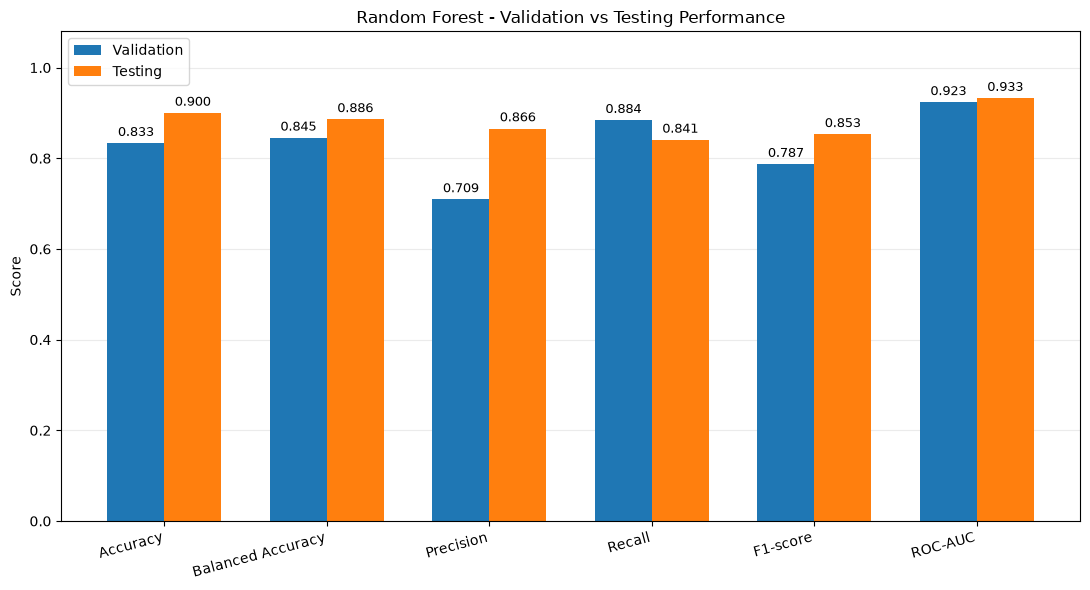


Saved to: /Users/omargutierrez/Luna Dataset Project/results/random_forest_validation_vs_testing.png


In [60]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Generate predictions for validation
validation_predictions = validation_random_forest.predict(X_validation)

validation_probabilities = validation_random_forest.predict_proba(
    X_validation
)[:, 1]

# Generate predictions for testing
testing_predictions = validation_random_forest.predict(X_test)

testing_probabilities = validation_random_forest.predict_proba(
    X_test
)[:, 1]

# Calculate validation metrics
validation_metrics = {
    "Accuracy": accuracy_score(y_validation, validation_predictions),
    "Balanced Accuracy": balanced_accuracy_score(y_validation, validation_predictions),
    "Precision": precision_score(y_validation, validation_predictions),
    "Recall": recall_score(y_validation, validation_predictions),
    "F1-score": f1_score(y_validation, validation_predictions),
    "ROC-AUC": roc_auc_score(y_validation, validation_probabilities)
}

# Calculate testing metrics
testing_metrics = {
    "Accuracy": accuracy_score(y_test, testing_predictions),
    "Balanced Accuracy": balanced_accuracy_score(y_test, testing_predictions),
    "Precision": precision_score(y_test, testing_predictions),
    "Recall": recall_score(y_test, testing_predictions),
    "F1-score": f1_score(y_test, testing_predictions),
    "ROC-AUC": roc_auc_score(y_test, testing_probabilities)
}

# Display the results
print("Random Forest - Validation vs Testing\n")

for metric_name in validation_metrics:
    print(
        f"{metric_name:20s} "
        f"Validation: {validation_metrics[metric_name]:.3f} | "
        f"Testing: {testing_metrics[metric_name]:.3f}"
    )

# Prepare the comparison chart
metric_names = list(validation_metrics.keys())

validation_values = list(validation_metrics.values())
testing_values = list(testing_metrics.values())

x_positions = np.arange(len(metric_names))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

validation_bars = ax.bar(
    x_positions - bar_width / 2,
    validation_values,
    bar_width,
    label="Validation"
)

testing_bars = ax.bar(
    x_positions + bar_width / 2,
    testing_values,
    bar_width,
    label="Testing"
)

# Display values above each bar
ax.bar_label(validation_bars, fmt="%.3f", padding=3, fontsize=9)
ax.bar_label(testing_bars, fmt="%.3f", padding=3, fontsize=9)

ax.set_title("Random Forest - Validation vs Testing Performance")
ax.set_ylabel("Score")
ax.set_xticks(x_positions)
ax.set_xticklabels(metric_names, rotation=15, ha="right")
ax.set_ylim(0, 1.08)
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

# Save the figure
output_path = (
    project_directory / "results" /
    "random_forest_validation_vs_testing.png"
)

fig.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()

print("\nSaved to:", output_path)

Testing samples: 200
Unique patients: 112
Bootstrap repetitions: 1000


,Metric,Testing Score,CI Lower,CI Upper
0,Accuracy,0.900,0.853,0.946
1,Balanced Accuracy,0.886,0.831,0.939
2,Precision,0.866,0.770,0.947
3,Recall,0.841,0.743,0.924
4,F1-score,0.853,0.774,0.917
5,ROC-AUC,0.933,0.885,0.974


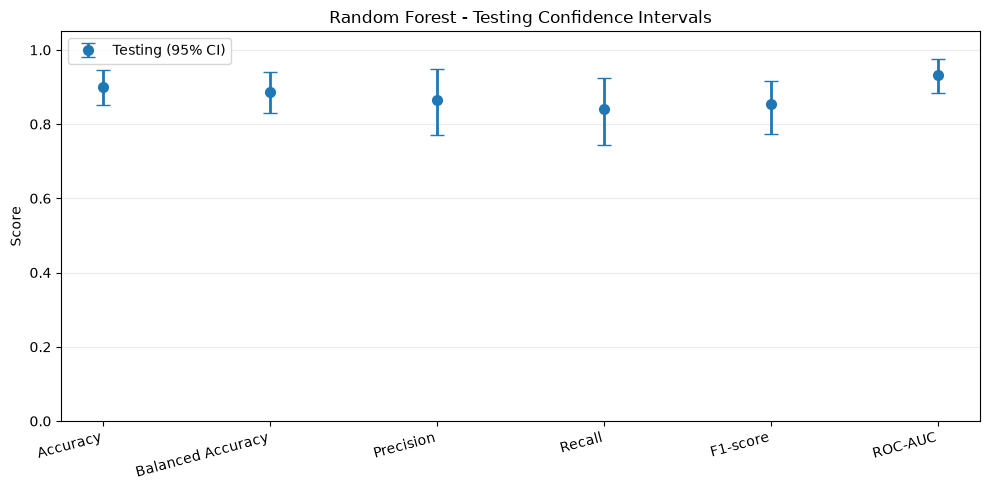

Saved to: /Users/omargutierrez/Luna Dataset Project/results/random_forest_testing_confidence_intervals.csv
Saved to: /Users/omargutierrez/Luna Dataset Project/results/random_forest_testing_confidence_intervals.png


In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Prepare testing data
X_test = final_testing_dataset[feature_columns]
y_test = final_testing_dataset["malignancy_label"].to_numpy()
patient_ids = final_testing_dataset["patient_id"].to_numpy()

# Predict using the selected model
test_predictions = validation_random_forest.predict(X_test)

test_probabilities = validation_random_forest.predict_proba(
    X_test
)[:, 1]

# Calculate original testing metrics
testing_metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Balanced Accuracy": balanced_accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions),
    "Recall": recall_score(y_test, test_predictions),
    "F1-score": f1_score(y_test, test_predictions),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities)
}

# Prepare patient-level bootstrap
random_generator = np.random.default_rng(42)
number_of_repetitions = 1000

unique_patients = np.unique(patient_ids)

patient_indices = {}

for patient_id in unique_patients:
    patient_indices[patient_id] = np.flatnonzero(
        patient_ids == patient_id
    )

bootstrap_results = {
    metric_name: []
    for metric_name in testing_metrics
}

# Bootstrap resampling
for repetition in range(number_of_repetitions):

    sampled_patients = random_generator.choice(
        unique_patients,
        size=len(unique_patients),
        replace=True
    )

    sampled_indices = np.concatenate([
        patient_indices[patient_id]
        for patient_id in sampled_patients
    ])

    sampled_labels = y_test[sampled_indices]
    sampled_predictions = test_predictions[sampled_indices]
    sampled_probabilities = test_probabilities[sampled_indices]

    bootstrap_results["Accuracy"].append(
        accuracy_score(sampled_labels, sampled_predictions)
    )

    bootstrap_results["Balanced Accuracy"].append(
        balanced_accuracy_score(sampled_labels, sampled_predictions)
    )

    bootstrap_results["Precision"].append(
        precision_score(
            sampled_labels,
            sampled_predictions,
            zero_division=0
        )
    )

    bootstrap_results["Recall"].append(
        recall_score(
            sampled_labels,
            sampled_predictions,
            zero_division=0
        )
    )

    bootstrap_results["F1-score"].append(
        f1_score(
            sampled_labels,
            sampled_predictions,
            zero_division=0
        )
    )

    # ROC-AUC requires both classes
    if len(np.unique(sampled_labels)) == 2:

        bootstrap_results["ROC-AUC"].append(
            roc_auc_score(
                sampled_labels,
                sampled_probabilities
            )
        )

# Calculate 95% confidence intervals
confidence_records = []

for metric_name, metric_value in testing_metrics.items():

    lower_bound, upper_bound = np.percentile(
        bootstrap_results[metric_name],
        [2.5, 97.5]
    )

    confidence_records.append({
        "Metric": metric_name,
        "Testing Score": metric_value,
        "CI Lower": lower_bound,
        "CI Upper": upper_bound
    })

confidence_table = pd.DataFrame(confidence_records)

print("Testing samples:", len(y_test))
print("Unique patients:", len(unique_patients))
print("Bootstrap repetitions:", number_of_repetitions)

display(confidence_table.round(3))

# Save results
output_path = (
    project_directory / "results" /
    "random_forest_testing_confidence_intervals.csv"
)

confidence_table.to_csv(output_path, index=False)

# Plot confidence intervals
metric_names = confidence_table["Metric"].tolist()
scores = confidence_table["Testing Score"].to_numpy()

lower_errors = (
    scores - confidence_table["CI Lower"].to_numpy()
)

upper_errors = (
    confidence_table["CI Upper"].to_numpy() - scores
)

error_ranges = np.array([lower_errors, upper_errors])

fig, ax = plt.subplots(figsize=(10, 5))

ax.errorbar(
    metric_names,
    scores,
    yerr=error_ranges,
    fmt="o",
    capsize=5,
    markersize=7,
    linewidth=2,
    label="Testing (95% CI)"
)

ax.set_title("Random Forest - Testing Confidence Intervals")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.xticks(rotation=15, ha="right")
plt.tight_layout()

# Save figure
figure_path = (
    project_directory / "results" /
    "random_forest_testing_confidence_intervals.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:", output_path)
print("Saved to:", figure_path)